<a href="https://colab.research.google.com/github/Protmdd/BD_OECE_PROYECTO_DM/blob/main/HITO_2_Proyecto_DM_OECE_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##GRUPO DIAMOND FINDERS ©

INTEGRANTES:

*Gianella Silvestre Nina   
*Andre de la Fuente   
*Luis Atto Pintado


---



**INDICE**

1. Problema, usuario y objetivo de análisis

2. Fuentes de datos y unidad de análisis

3. Claves y plan de integración

4. Diagnóstico preliminar de calidad

5. Código central

    * carga de datos
    * inspección de las fuentes
    * revisión de duplicados
    * validación de las claves
    * integración de las fuentes


6. Visualizaciones iniciales y hallazgos

7. Decisiones de limpieza, transformaciones justificadas y matriz analítica

8. Proximos pasos

---






---

##<font color='green'>**1. Problema, usuario y objetivo de análisis**

---



TITULO: **Segmentación de proveedores en contrataciones de municipalidades provinciales del Perú según patrones de participación y adjudicación, 2021–2025**

##<font color='blue'> Problema

Las empresas y proveedores que participan en las contrataciones de las municipalidades provinciales del Perú presentan comportamientos heterogéneos. Algunos participan de manera ocasional, mientras que otros presentan una participación recurrente, obtienen múltiples adjudicaciones, manejan mayores montos contratados o participan en diferentes territorios y rubros.

Sin embargo, la información registrada en el SEACE se encuentra distribuida entre múltiples procesos de contratación, ofertantes y adjudicaciones, lo que dificulta identificar de manera directa los diferentes perfiles de proveedores que participan en este mercado.

Por ello, se busca transformar los registros individuales de contratación en una visión agregada a nivel de proveedor, permitiendo analizar su comportamiento durante el periodo 2021–2025 e identificar grupos de proveedores con características similares.

##<font color='blue'> Usuario del análisis

El principal usuario del análisis es el **OECE**, y de manera complementaria las entidades públicas responsables de la gestión de contrataciones.

Los resultados pueden servir para comprender mejor la composición y comportamiento del mercado de proveedores, identificar perfiles diferenciados y generar información que contribuya al monitoreo y análisis de las contrataciones públicas.

##<font color='blue'> Objetivo general

**Identificar y caracterizar segmentos naturales de proveedores que participan en las contrataciones de municipalidades provinciales del Perú durante 2021–2025, utilizando sus patrones de participación, adjudicación, escala económica y alcance territorial.**

##<font color='blue'> Objetivos específicos

1. **Construir un perfil agregado por proveedor** a partir de los registros de participación y adjudicación de las contrataciones.

2. **Identificar patrones de comportamiento** relacionados con frecuencia de participación, tasa de adjudicación, monto adjudicado, diversificación territorial y participación en consorcios.

3. **Aplicar técnicas de clustering** para identificar grupos de proveedores con características similares.

4. **Caracterizar y comparar los segmentos encontrados**, identificando las variables que diferencian a cada perfil.

5. **Analizar variables complementarias**, como las penalidades, para determinar si existen diferencias entre los segmentos identificados.

##<font color='blue'> Pregunta principal

**¿Qué segmentos naturales de proveedores pueden identificarse en las contrataciones de municipalidades provinciales del Perú durante 2021–2025 y qué características definen a cada perfil?**


---

## <font color=green>**2. Fuentes de datos y unidad de análisis</font>**

---



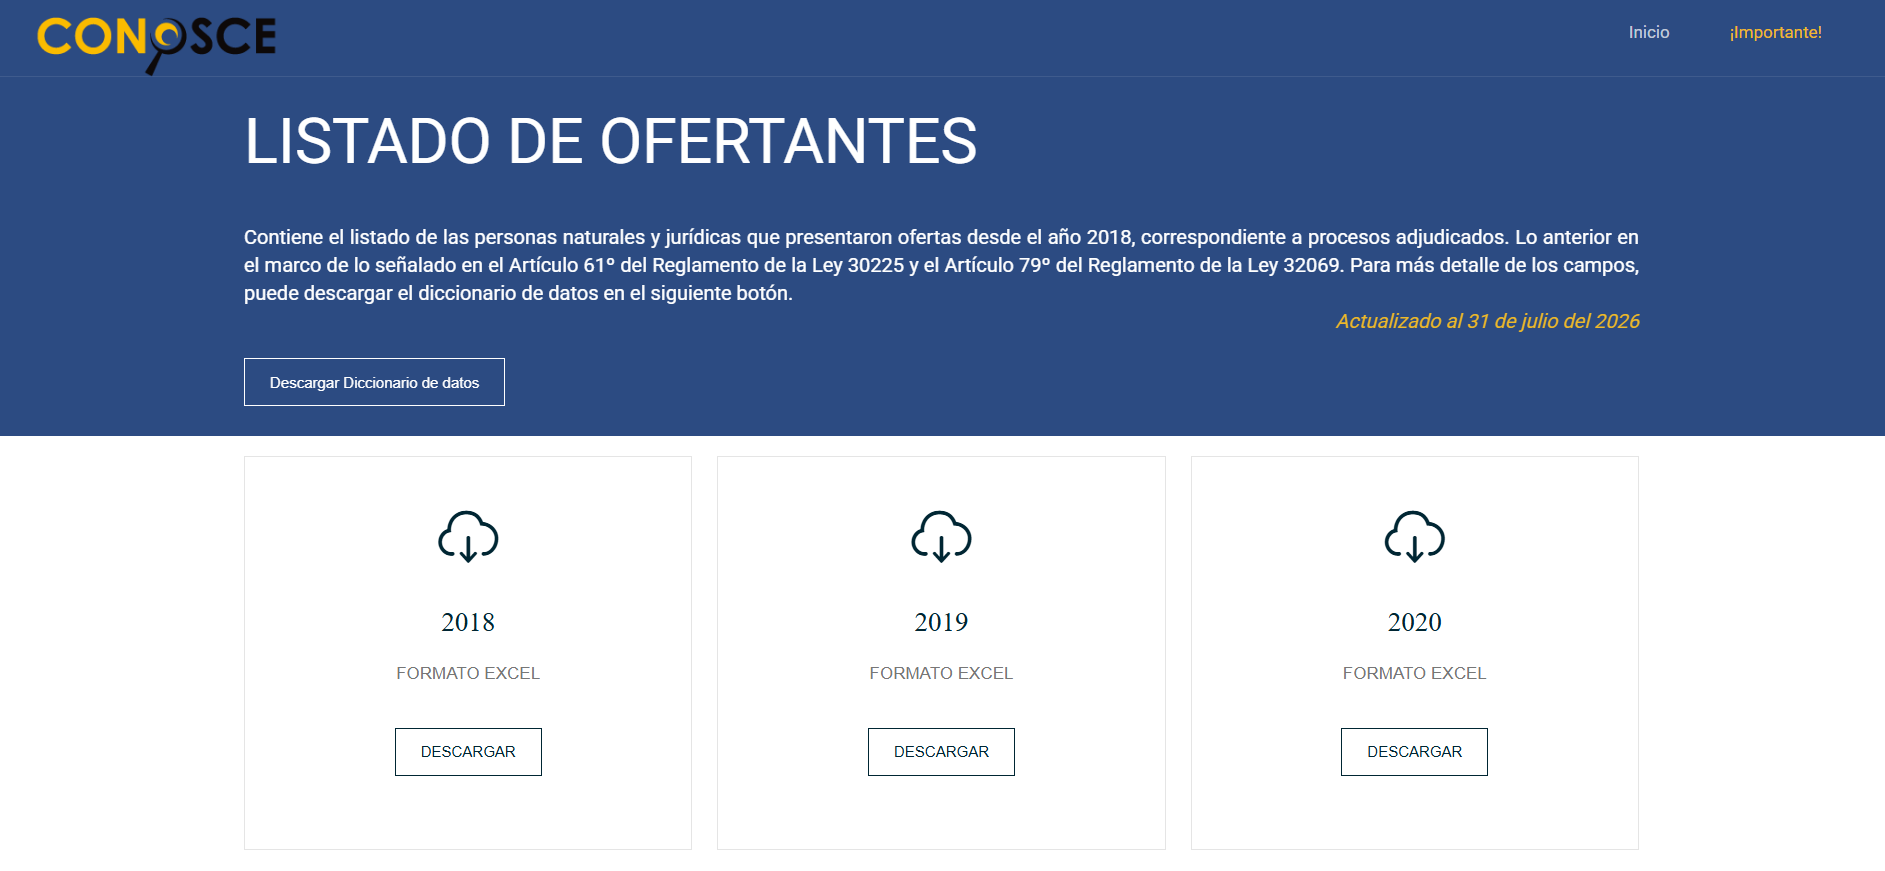

##<font color='blue'> Unidad de análisis

La **unidad de análisis es el proveedor postor**, considerando principalmente empresas y otros proveedores que participan en contrataciones de municipalidades provinciales del Perú.

Cada proveedor constituye una observación en el dataset final. Para cada uno se agregan sus características y comportamiento durante el periodo 2021–2025, incluyendo variables como número de convocatorias en las que participó, adjudicaciones obtenidas, tasa de adjudicación, monto total adjudicado, número de rubros, alcance territorial y participación en consorcios.

De esta manera, el análisis no busca segmentar procesos de contratación individuales, sino **segmentar proveedores según sus patrones agregados de participación y adjudicación**.


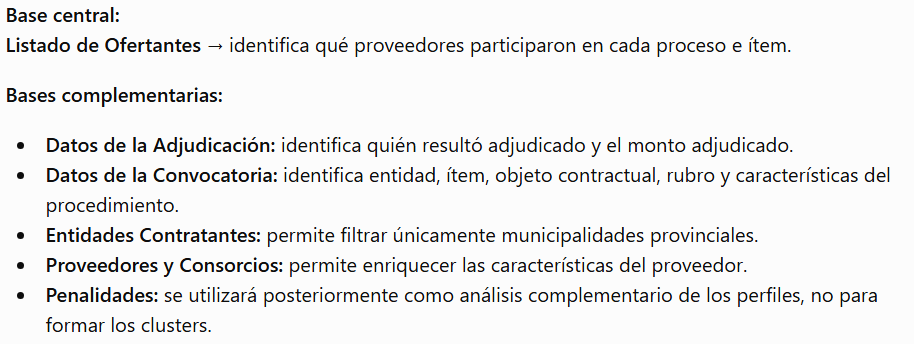

In [ ]:
# @title
import os

# Install Git LFS
!apt-get update -qq
!apt-get install -qq git-lfs
!git lfs install

# Remove existing repository if it exists to ensure a clean clone with LFS
if os.path.exists("/content/BD_OECE_PROYECTO_DM"):
    !rm -rf "/content/BD_OECE_PROYECTO_DM"

# Clone the repository (Git LFS should now handle large files)
!git clone https://github.com/Protmdd/BD_OECE_PROYECTO_DM.git
# Pull Git LFS files explicitly to ensure all large files are downloaded
!git lfs pull

try:
    import python_calamine
except ImportError:
    !pip install -q python-calamine

# ============================================================
# LECTURA Y CONCATENACIÓN MULTI-AÑO
# ============================================================
import glob, warnings, unicodedata, re
import pandas as pd
import numpy as np
warnings.filterwarnings('ignore')

BASE = "/content/BD_OECE_PROYECTO_DM/Bases de Datos Proyecto DM"
CACHE = "/content/cache"
os.makedirs(CACHE, exist_ok=True)

def norm_cols(df):
    def limpia(c):
        c = str(c).strip()
        c = unicodedata.normalize('NFKD', c).encode('ascii', 'ignore').decode('ascii')
        c = c.lower()
        c = c.replace('/', '_').replace('-', '_')
        c = '_'.join(c.split())
        c = ''.join(ch for ch in c if ch.isalnum() or ch == '_')
        return c.strip('_')
    df = df.copy()
    df.columns = [limpia(c) for c in df.columns]
    df = df.loc[:, ~df.columns.str.startswith('unnamed')]
    df = df.dropna(axis=1, how='all')
    df = df.rename(columns={'ano': 'anio', 'ao': 'anio'})
    df = df.loc[:, ~df.columns.duplicated()]
    return df

def leer_multianio(patron, base=BASE, agregar_anio=True, usar_cache=True):
    cache_file = os.path.join(CACHE, patron.replace('*', '').replace('.xlsx', '') + '.parquet')

    if usar_cache and os.path.exists(cache_file):
        out = pd.read_parquet(cache_file)
        print(f"  ⚡ leído desde cache: {cache_file} -> {out.shape[0]:,} filas x {out.shape[1]} cols\n")
        return out

    files = sorted(glob.glob(os.path.join(base, patron)))
    if not files:
        print(f"  Sin archivos para el patrón: {patron}")
        return pd.DataFrame()

    dfs, sets_cols = [], []
    for f in files:
        nombre = os.path.basename(f)
        try:
            df = norm_cols(pd.read_excel(f, engine='calamine'))
        except Exception as e:
            print(f"  ❌ Error al leer {nombre}: {e}. Se omite este archivo.")
            continue

        if agregar_anio:
            digits = ''.join(ch for ch in nombre if ch.isdigit())
            df['anio_archivo'] = digits[:4] if len(digits) >= 4 else None
            df['archivo_origen'] = nombre

        sets_cols.append(set(df.columns))
        print(f"  ✔ {nombre:<48} -> {df.shape[0]:>9,} filas | {df.shape[1]:>2} cols")
        dfs.append(df)

    if not dfs:
        print(f"  No se pudieron leer archivos válidos para el patrón: {patron}")
        return pd.DataFrame()

    comunes, todas = set.intersection(*sets_cols), set.union(*sets_cols)
    if todas - comunes:
        print(f"  Columnas no presentes en todos los años: {sorted(todas - comunes)}")

    out = pd.concat(dfs, ignore_index=True, sort=False)
    print(f"  ➔ CONCATENADO: {out.shape[0]:,} filas x {out.shape[1]} cols\n")

    if usar_cache:
        out.to_parquet(cache_file)

    return out

def leer_penalidades(nombre="penalidades.csv", base=BASE, sep='|',
                     col_texto=6, encodings=('utf-8', 'utf-8-sig', 'latin-1'),
                     usar_cache=True):
    cache_file = os.path.join(CACHE, 'penalidades.parquet')
    if usar_cache and os.path.exists(cache_file):
        df = pd.read_parquet(cache_file)
        print(f"  ✔ leído desde cache: {cache_file} -> {df.shape[0]:,} filas | {df.shape[1]} cols\n")
        return df

    ruta = os.path.join(base, nombre)

    for enc in encodings:
        try:
            with open(ruta, 'r', encoding=enc) as fh:
                lineas = fh.read().splitlines()
            break
        except UnicodeDecodeError:
            continue

    header = [h.strip() for h in lineas[0].split(sep)]
    ncol = len(header)
    body = pd.Series([l for l in lineas[1:] if l.strip()])

    # separa filas bien formadas (vectorizado) de las rotas (loop solo ahí)
    n_pipes = body.str.count(re.escape(sep))
    ok_mask = n_pipes == (ncol - 1)

    df_ok = body[ok_mask].str.split(sep, expand=True)
    df_ok.columns = header

    filas_mal, reparadas, descartadas = [], 0, 0
    for ln in body[~ok_mask]:
        p = ln.split(sep)
        if len(p) > ncol:
            n_extra = len(p) - ncol
            p = (p[:col_texto]
                 + [sep.join(p[col_texto: col_texto + 1 + n_extra])]
                 + p[col_texto + 1 + n_extra:])
            reparadas += 1
        else:
            p = p + [None] * (ncol - len(p))
            descartadas += 1
        filas_mal.append(p)

    df_mal = pd.DataFrame(filas_mal, columns=header) if filas_mal else pd.DataFrame(columns=header)

    df = pd.concat([df_ok, df_mal], ignore_index=True)
    df = df.apply(lambda c: c.str.strip() if c.dtype == 'object' else c)
    df = norm_cols(df)

    # tipos
    df['monto'] = pd.to_numeric(df['monto'], errors='coerce')
    df['fecha_penalidad'] = pd.to_datetime(df['fecha_penalidad'],
                                           format='%d/%m/%y', errors='coerce')
    df['ruc_contratista'] = (df['ruc_contratista'].astype(str)
                             .str.replace(r'\.0$', '', regex=True).str.strip())

    print(f"  ✔ {nombre} (enc={enc}) -> {df.shape[0]:,} filas | {df.shape[1]} cols")
    print(f"     filas reparadas (| extra): {reparadas:,} | filas incompletas: {descartadas:,}")
    print(f"     columnas: {list(df.columns)}\n")

    if usar_cache:
        df.to_parquet(cache_file)

    return df


# ------------------------------------------------------------
# 3) Lector de CSV simple (entidades)
# ------------------------------------------------------------
def leer_csv(nombre, base=BASE, sep='|'):
    ruta = os.path.join(base, nombre)
    for enc in ('utf-8', 'utf-8-sig', 'latin-1'):
        try:
            df = norm_cols(pd.read_csv(ruta, sep=sep, encoding=enc,
                                       engine='python', on_bad_lines='skip', dtype=str))
            print(f"  ✔ {nombre} (enc={enc}) -> {df.shape[0]:,} filas | {df.shape[1]} cols\n")
            return df
        except UnicodeDecodeError:
            continue
    raise ValueError(f"No se pudo leer {nombre}")


# ============================================================
# GENERACIÓN DE LOS DATAFRAMES
# ============================================================
print("📂 ADJUDICACIONES:");  df_adj  = leer_multianio("CONOSCE_ADJUDICACIONES*.xlsx")
print("📂 POSTORES:");        df_post = leer_multianio("CONOSCE_POSTOR*.xlsx")
print("📂 CONSORCIOS:");      df_cons = leer_multianio("CONOSCE_CONSORCIO*.xlsx")
print("📂 CONVOCATORIAS:");   df_conv = leer_multianio("CONOSCE_CONVOCATORIAS*.xlsx")
print("📂 ENTIDADES:");       df_ent  = leer_csv("entidades_contratantes.csv")
print("📂 PENALIDADES:");     df_pen  = leer_penalidades("penalidades.csv")


# ============================================================
# RESUMEN + VERIFICACIÓN
# ============================================================
dfs = {'df_adj': df_adj, 'df_post': df_post, 'df_cons': df_cons,
       'df_conv': df_conv, 'df_ent': df_ent, 'df_pen': df_pen}

resumen_dfs = pd.DataFrame([{'DataFrame': k,
                             'Filas': v.shape[0],
                             'Columnas': v.shape[1],
                             'MB': round(v.memory_usage(deep=True).sum() / 1e6, 1)}
                            for k, v in dfs.items()])

print("=" * 70)
print("RESUMEN DE DATAFRAMES GENERADOS")
print("=" * 70)
print(resumen_dfs.to_string(index=False))

for k, v in dfs.items():
    print(f"\n{k} ({v.shape[0]:,} x {v.shape[1]}):\n  {list(v.columns)}")

for nombre, d in [('ADJUDICACIONES', df_adj), ('POSTORES', df_post),
                  ('CONSORCIOS', df_cons), ('CONVOCATORIAS', df_conv)]:
    if 'anio_archivo' in d.columns:
        print(f"\n{nombre} — registros por año:")
        print(d['anio_archivo'].value_counts().sort_index().to_string())

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Git LFS initialized.
Cloning into 'BD_OECE_PROYECTO_DM'...
remote: Enumerating objects: 62, done.
remote: Counting objects: 100% (62/62), done.
remote: Compressing objects: 100% (60/60), done.
remote: Total 62 (delta 11), reused 33 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (62/62), 1.37 MiB | 4.95 MiB/s, done.
Resolving deltas: 100% (11/11), done.
Filtering content: 100% (22/22), 237.44 MiB | 38.85 MiB/s, done.
Not in a Git repository.
📂 ADJUDICACIONES:
  ⚡ leído desde cache: /content/cache/CONOSCE_ADJUDICACIONES.parquet -> 326,770 filas x 27 cols

📂 POSTORES:
  ⚡ leído desde cache: /content/cache/CONOSCE_POSTOR.parquet -> 1,049,868 filas x 8 cols

📂 CONSORCIOS:
  ⚡ leído desde cache: /content/cache/CONOSCE_CONSORCIO.parquet -> 89,579 filas x 7 cols

📂 CONVOCATORIAS:
  ⚡ leído desde c



---


## <font color=green>**3. Claves y plan de integración - DIAGRAMA ENTIDAD RELACIÓN**






---



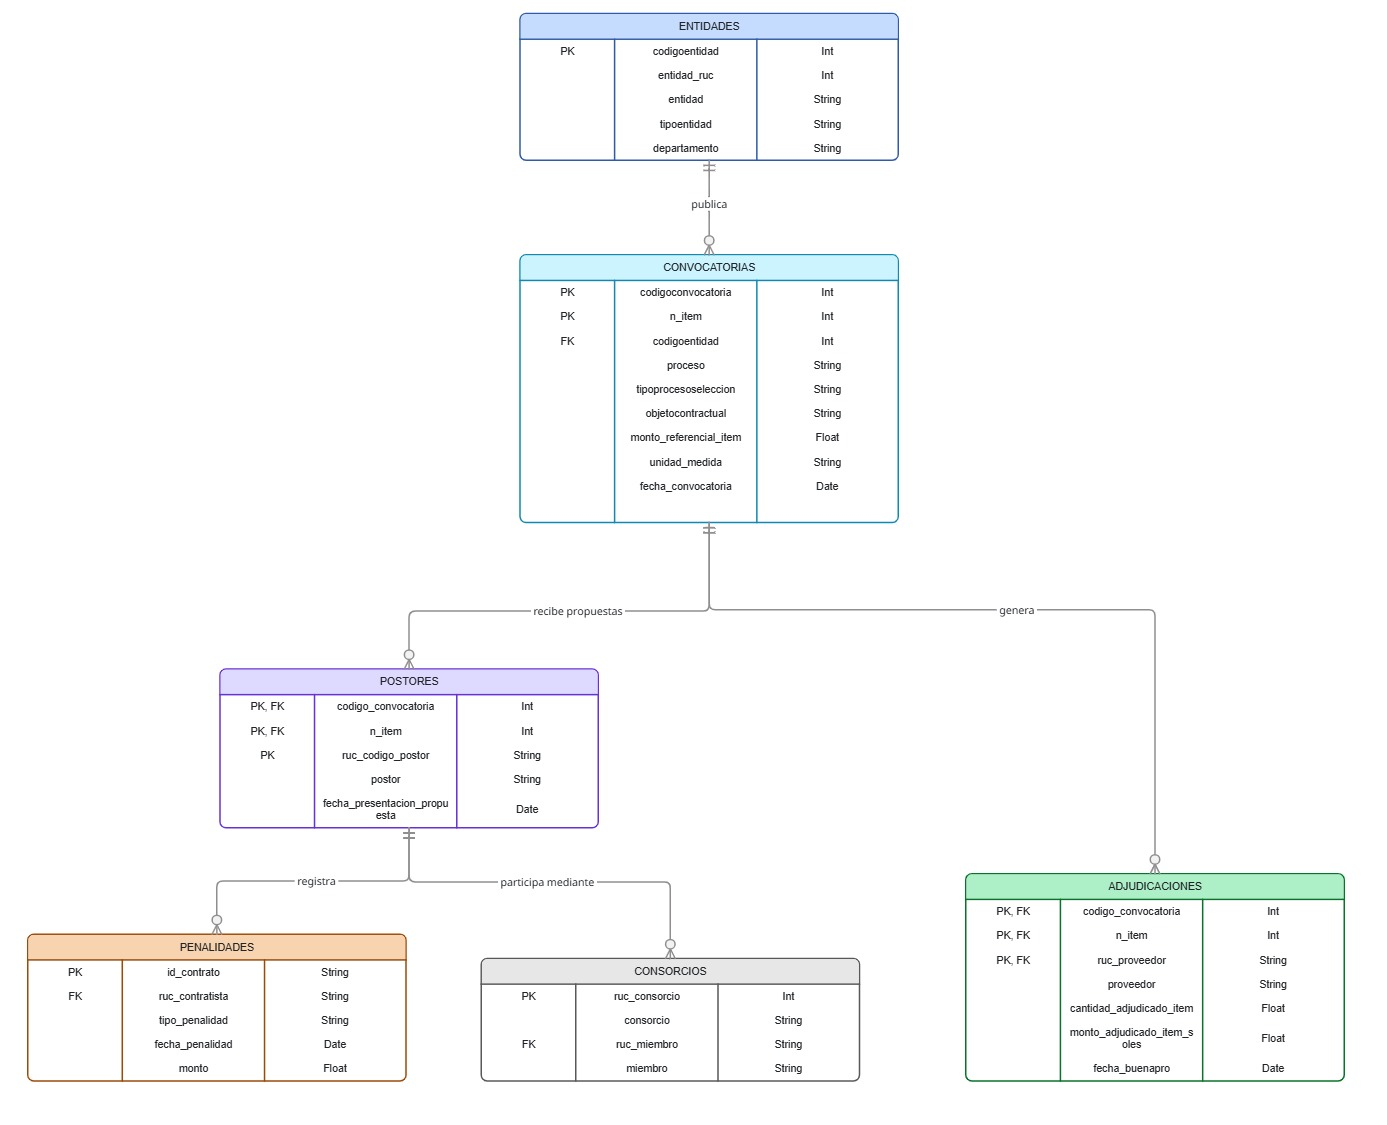



---

## <font color=green>**4. Diagnóstico preliminar de calidad**</font>

---



## <font color=blue>Resumen Detallado por Fuente de Datos</font>

A continuación, se presenta un resumen exhaustivo para cada DataFrame, que incluye:

* **Dimensiones:** Número de filas y columnas.

* **Tipos de Datos:** El tipo de dato inferido por Pandas para cada columna.

* **Valores Distintos:** El número de valores únicos en cada columna.

* **Ejemplos de Valores:** Las primeras 5 filas del DataFrame para una vista rápida de los datos.[texto del enlace](https://)

In [ ]:
# @title
def summarize_dataframe_full(df, name):
    print(f"\n{'='*70}\nRESUMEN COMPLETO PARA: {name}\n{'='*70}")

    # Dimensiones
    print(f"\nDimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas")

    # Tipos de Datos
    print("\nTipos de Datos:")
    display(df.dtypes.to_frame(name='Tipo de Dato'))

    # Valores Distintos
    print("\nValores Distintos por Columna:")
    display(df.nunique().to_frame(name='Valores Únicos'))

    # Ejemplos de Valores
    print("\nEjemplos de Valores (primeras 5 filas):")
    display(df.head())


# Aplicar la función a cada DataFrame
for name, df in dfs.items():
    summarize_dataframe_full(df, name)


RESUMEN COMPLETO PARA: df_adj

Dimensiones: 326,770 filas x 27 columnas

Tipos de Datos:


,Tipo de Dato
codigoentidad,int64
entidad_ruc,int64
entidad,object
tipoentidad,object
entidad_departamento,object
codigoconvocatoria,int64
objetocontractual,object
tipoprocesoseleccion,object
proceso,object
descripcion_proceso,object



Valores Distintos por Columna:


,Valores Únicos
codigoentidad,3044
entidad_ruc,3044
entidad,3044
tipoentidad,5
entidad_departamento,25
codigoconvocatoria,286572
objetocontractual,4
tipoprocesoseleccion,43
proceso,259817
descripcion_proceso,273947



Ejemplos de Valores (primeras 5 filas):


...

,Tipo de Dato
id_contrato,object
ruc_contratista,object
tipo_penalidad,object
objeto_contrato,object
entidad_contratante,object
fecha_penalidad,datetime64[ns]
descripcion_motivo,object
monto,float64



Valores Distintos por Columna:


,Valores Únicos
id_contrato,5125
ruc_contratista,3233
tipo_penalidad,2
objeto_contrato,4
entidad_contratante,628
fecha_penalidad,1581
descripcion_motivo,8361
monto,1938



Ejemplos de Valores (primeras 5 filas):


,id_contrato,ruc_contratista,tipo_penalidad,objeto_contrato,entidad_contratante,fecha_penalidad,descripcion_motivo,monto
0,2255476,20536426168,Otra Penalidad,Servicio,PROYECTO ESPECIAL DE INVERSION PUBLICA ESCUELA...,2026-03-10,PENALIDAD POR INCIDENCIA ADMINISTRATIVA ASOCIA...,220.0
1,2330522,20553404631,Por Mora,Servicio,PROYECTO ESPECIAL DE INVERSION PUBLICA ESCUELA...,2025-08-05,SE REGISTRA LA APLICACION DE PENALIDAD EN FUNC...,NaN
2,2330522,20553404631,Por Mora,Servicio,PROYECTO ESPECIAL DE INVERSION PUBLICA ESCUELA...,2025-08-27,SE REGISTRA LA APLICACION DE PENALIDAD EN FUNC...,NaN
3,2320073,20536426168,Otra Penalidad,Servicio,PROYECTO ESPECIAL DE INVERSION PUBLICA ESCUELA...,2026-03-25,PENALIDAD POR INCIDENCIA ADMINISTRATIVA ASOCIA...,220.0
4,2234695,10283047682,Otra Penalidad,Consultoría de Obra,MUNICIPALIDAD DISTRITAL DE MEGANTONI,2025-02-15,APLICACION DE PENALIDAD,2575.0




---


## <font color=green> **5. Código central**

---



### Detección Específica de Problemas de Calidad de Datos

## <font color=blue> 5.1 Valores Faltantes (Missing Values)

In [ ]:
# @title
print("\n--- df_adj: Adjudicaciones ---")
missing_adj = df_adj.isnull().sum()
missing_adj = missing_adj[missing_adj > 0]
if not missing_adj.empty:
    missing_adj_pct = (missing_adj / len(df_adj)) * 100
    missing_adj_df = pd.DataFrame({'Count': missing_adj, 'Percentage': missing_adj_pct})
    display(missing_adj_df.sort_values(by='Count', ascending=False))
else:
    print("No hay valores faltantes en df_adj.")

print("\n--- df_post: Postores ---")
missing_post = df_post.isnull().sum()
missing_post = missing_post[missing_post > 0]
if not missing_post.empty:
    missing_post_pct = (missing_post / len(df_post)) * 100
    missing_post_df = pd.DataFrame({'Count': missing_post, 'Percentage': missing_post_pct})
    display(missing_post_df.sort_values(by='Count', ascending=False))
else:
    print("No hay valores faltantes en df_post.")

print("\n--- df_cons: Consorcios ---")
missing_cons = df_cons.isnull().sum()
missing_cons = missing_cons[missing_cons > 0]
if not missing_cons.empty:
    missing_cons_pct = (missing_cons / len(df_cons)) * 100
    missing_cons_df = pd.DataFrame({'Count': missing_cons, 'Percentage': missing_cons_pct})
    display(missing_cons_df.sort_values(by='Count', ascending=False))
else:
    print("No hay valores faltantes en df_cons.")

print("\n--- df_conv: Convocatorias ---")
missing_conv = df_conv.isnull().sum()
missing_conv = missing_conv[missing_conv > 0]
if not missing_conv.empty:
    missing_conv_pct = (missing_conv / len(df_conv)) * 100
    missing_conv_df = pd.DataFrame({'Count': missing_conv, 'Percentage': missing_conv_pct})
    display(missing_conv_df.sort_values(by='Count', ascending=False))
else:
    print("No hay valores faltantes en df_conv.")

print("\n--- df_ent: Entidades ---")
missing_ent = df_ent.isnull().sum()
missing_ent = missing_ent[missing_ent > 0]
if not missing_ent.empty:
    missing_ent_pct = (missing_ent / len(df_ent)) * 100
    missing_ent_df = pd.DataFrame({'Count': missing_ent, 'Percentage': missing_ent_pct})
    display(missing_ent_df.sort_values(by='Count', ascending=False))
else:
    print("No hay valores faltantes en df_ent.")

print("\n--- df_pen: Penalidades ---")
missing_pen = df_pen.isnull().sum()
missing_pen = missing_pen[missing_pen > 0]
if not missing_pen.empty:
    missing_pen_pct = (missing_pen / len(df_pen)) * 100
    missing_pen_df = pd.DataFrame({'Count': missing_pen, 'Percentage': missing_pen_pct})
    display(missing_pen_df.sort_values(by='Count', ascending=False))
else:
    print("No hay valores faltantes en df_pen.")


--- df_adj: Adjudicaciones ---


,Count,Percentage
fecha_consentimiento_bp,2914,0.891759
departamento_item,1657,0.507084
fecha_buenapro,80,0.024482
monto_referencial_item_soles,3,0.000918
tipo_proveedor,1,0.000306



--- df_post: Postores ---
No hay valores faltantes en df_post.

--- df_cons: Consorcios ---
No hay valores faltantes en df_cons.

--- df_conv: Convocatorias ---


,Count,Percentage
fechaintegracionbases,124256,38.265583
codigoitem,49587,15.270695
itemcubso,49587,15.270695
fechapresentacionpropuesta,39562,12.183420
distrito_item,1653,0.509054
departamento_item,1653,0.509054
provincia_item,1653,0.509054
sistema_contratacion,68,0.020941



--- df_ent: Entidades ---


,Count,Percentage
codigo_siaf,352,10.466845



--- df_pen: Penalidades ---


,Count,Percentage
monto,7332,52.375170
tipo_penalidad,1,0.007143
objeto_contrato,1,0.007143
entidad_contratante,1,0.007143
fecha_penalidad,1,0.007143
descripcion_motivo,1,0.007143


## <font color=blue>5.2 Duplicados

In [ ]:
# @title
print("### Detección de Filas Duplicadas ###\n")

df_conv = df_conv.rename(columns={'codigoconvocatoria': 'codigo_convocatoria'})
df_adj = df_adj.rename(columns={'codigoconvocatoria': 'codigo_convocatoria'})
df_post = df_post.rename(columns={'ruc_codigo_postor': 'ruc_proveedor'})

for name, df in dfs.items():
    total_duplicados = df.duplicated().sum()
    if total_duplicados > 0:
        print(f"DataFrame '{name}': {total_duplicados:,} filas completamente duplicadas.")
    else:
        print(f"DataFrame '{name}': No se encontraron filas completamente duplicadas.")

# Penalidades: los duplicados exactos SÍ se eliminan aquí, antes de cualquier
# groupby, para no contar la misma penalidad (y su monto) más de una vez.
n_dup_pen = df_pen.duplicated().sum()
if n_dup_pen > 0:
    print(f"\ndf_pen: eliminando {n_dup_pen:,} filas completamente duplicadas antes de usarlas en agregaciones.")
    df_pen = df_pen.drop_duplicates().reset_index(drop=True)
    dfs['df_pen'] = df_pen

# Duplicados por llave de integración (no por fila completa). Si aquí aparece
# algo > 0, el merge de la sección de integración va a inflar filas si no se
# resuelve antes (ver dedup_por_llave en la celda de integración Nivel 1).
print("\nDuplicados por llave de integración (antes de mergear):")
print(f"  df_conv por (codigo_convocatoria, n_item): {df_conv.duplicated(['codigo_convocatoria', 'n_item']).sum():,}")
print(f"  df_adj  por (codigo_convocatoria, n_item, ruc_proveedor_ganador): {df_adj.duplicated(['codigo_convocatoria', 'n_item','ruc_proveedor']).sum():,}")
print(f"  df_post por (codigo_convocatoria, n_item, ruc_proveedor): {df_post.duplicated(['codigo_convocatoria','fechaconvocatoria', 'n_item','ruc_proveedor']).sum():,}")

### Detección de Filas Duplicadas ###

DataFrame 'df_adj': No se encontraron filas completamente duplicadas.
DataFrame 'df_post': No se encontraron filas completamente duplicadas.
DataFrame 'df_cons': No se encontraron filas completamente duplicadas.
DataFrame 'df_conv': No se encontraron filas completamente duplicadas.
DataFrame 'df_ent': No se encontraron filas completamente duplicadas.
DataFrame 'df_pen': 367 filas completamente duplicadas.

df_pen: eliminando 367 filas completamente duplicadas antes de usarlas en agregaciones.

Duplicados por llave de integración (antes de mergear):
  df_conv por (codigo_convocatoria, n_item): 0
  df_adj  por (codigo_convocatoria, n_item, ruc_proveedor_ganador): 3
  df_post por (codigo_convocatoria, n_item, ruc_proveedor): 0


## <font color=blue> 5.3 Tipos Incorrectos y Errores de Registro (Coerción a NaN/NaT)

In [ ]:
# @title
print("### Detección de Errores de Tipo y Coerción ###\n")
def check_type_coercion(df, df_name):
    # columnas que por su nombre/uso deberían ser numéricas o fecha.
    # 'ruc' se excluye a propósito: el RUC se trata como texto (para no perder
    # ceros a la izquierda, ver celda de estandarización de llaves), así que
    # marcarlo como "error" cuando no es numérico sería un falso positivo.
    cols_esperado_numerico = [c for c in df.columns
                               if any(k in c.lower() for k in ['monto', 'cantidad', 'codigo', 'n_item'])
                               and 'ruc' not in c.lower()]
    cols_esperado_fecha    = [c for c in df.columns if 'fecha' in c.lower()]

    for col in cols_esperado_numerico:
        if pd.api.types.is_numeric_dtype(df[col].dtype):
            continue
        temp_numeric = pd.to_numeric(df[col], errors='coerce')
        numeric_errors = temp_numeric.isnull() & df[col].notnull()
        if numeric_errors.any():
            print(f"DataFrame '{df_name}', Columna '{col}' (Numérico): {numeric_errors.sum():,} valores no numéricos. Ejemplos: {df[col][numeric_errors].head().tolist()}")

    for col in cols_esperado_fecha:
        if pd.api.types.is_datetime64_any_dtype(df[col].dtype):
            continue
        temp_datetime = pd.to_datetime(df[col], errors='coerce')
        datetime_errors = temp_datetime.isnull() & df[col].notnull()
        if datetime_errors.any():
            print(f"DataFrame '{df_name}', Columna '{col}' (Fecha): {datetime_errors.sum():,} valores no-fecha. Ejemplos: {df[col][datetime_errors].head().tolist()}")

for name, df in dfs.items():
    print(f"Analizando DataFrame: {name}")
    check_type_coercion(df, name)
    print("-" * 50)


### Detección de Errores de Tipo y Coerción ###

Analizando DataFrame: df_adj
DataFrame 'df_adj', Columna 'descripcion_item' (Numérico): 326,735 valores no numéricos. Ejemplos: ['SERVICIO DE MANTENIMIENTO PREVENTIVO Y CORRECTIVO DE LA RED DE ENERGIA DE ALIMENTACION PARA LOS SISTEMAS DE AIRE ACONDICIONADO DE LAS 3 UCIS DEL HMC PP-135', 'BOLSA DE POLIETILENO BIODEGRADABLE VERDE DE 75 L', 'SUSCRIPCION A LA BASE DE DATOS E-LIBRO', 'CONTRATACION DE SERVICIO DE CONSULTORIA OBRA PARA LA ELABORACI¿N DE EXPEDIENTE T¿CNICO DEL PROYECTO ¿MEJORAMIENTO Y AMPLIACION DEL SERVICIO EDUCATIVO DE NIVEL INICIAL EN LA INSTITUCION EDUCATIVA N¿ 344 DE LA LOCALIDAD DE TACA, DEL DISTRITO DE CANARIA, PROVINCIA DE VICTOR FAJARDO, DEPARTAMENTO DE AYACUCHO¿', 'ELABORACI¿N DE EXPEDIENTE T¿CNICO:  ¿MEJORAMIENTO Y AMPLIACION DEL SERVICIO EDUCATIVO DEL NIVEL SECUNDARIO DE LA I.E. NUESTRA SE¿ORA DEL CARMEN DEL DISTRITO DE IMPERIAL, PROVINCIA DE CA¿ETE, DEPARTAMENTO DE LIMA¿ CUI N¿ 2338999']
DataFrame 'df_adj', Columna 

## <font color=blue> 5.4 Valores Fuera de Rango y Outliers (Valores Atípicos)

In [ ]:
# @title
print("### Detección de Outliers (IQR) y Valores Fuera de Rango ###\n")

def es_columna_id_o_binaria(col, serie):
    """Columnas identificadoras (codigo/ruc/n_item/anio) o binarias 0/1:
    el IQR no tiene interpretación estadística sobre ellas."""
    nombre = col.lower()
    if any(p in nombre for p in ['codigo', 'ruc', 'n_item', 'anio', 'id_']):
        return True
    valores = serie.dropna().unique()
    if len(valores) > 0 and set(valores).issubset({0, 1}):
        return True
    return False

def detect_outliers_and_range(df, df_name):
    print(f"Analizando DataFrame: {df_name}")
    numerical_cols = df.select_dtypes(include=['number']).columns

    for col in numerical_cols:
        if es_columna_id_o_binaria(col, df[col]):
            continue

        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][col]

        if not outliers.empty:
            # los outliers se reportan como alerta para revisión, no se eliminan
            # automáticamente: un proveedor con montos/participaciones muy altos
            # puede ser un caso real relevante para el clustering.
            print(f"Columna '{col}': {len(outliers):,} valores atípicos (IQR) detectados. Ejemplos: {outliers.head().tolist()}")

        if 'monto' in col or 'cantidad' in col:
            negative_values = df[df[col] < 0][col]
            if not negative_values.empty:
                print(f"Columna '{col}': {len(negative_values):,} valores negativos detectados (fuera de rango esperado). Ejemplos: {negative_values.head().tolist()}")
    print("-" * 50)

for name, df in dfs.items():
    detect_outliers_and_range(df, name)


### Detección de Outliers (IQR) y Valores Fuera de Rango ###

Analizando DataFrame: df_adj
Columna 'cantidad_adjudicado_item': 72,612 valores atípicos (IQR) detectados. Ejemplos: [539339.0, 1120.0, 3220.14, 94899.0, 96720.0]
Columna 'monto_referencial_item_soles': 45,619 valores atípicos (IQR) detectados. Ejemplos: [1240479.7, 1360219.0, 3060372.0, 4000000.0, 1830000.0]
Columna 'monto_adjudicado_item_soles': 44,507 valores atípicos (IQR) detectados. Ejemplos: [1342504.5, 3060372.0, 826560.0, 3456789.0, 1830000.0]
--------------------------------------------------
Analizando DataFrame: df_post
--------------------------------------------------
Analizando DataFrame: df_cons
--------------------------------------------------
Analizando DataFrame: df_conv
Columna 'montoreferencial': 48,946 valores atípicos (IQR) detectados. Ejemplos: [2389158.48, 1347287.01, 7856400.0, 21537948.12, 6561500.0]
Columna 'monto_referencial_item': 44,355 valores atípicos (IQR) detectados. Ejemplos: [1112298.68,

## <font color=blue> 5.5 Categorías Raras e Inconsistencias (Value Counts)

In [ ]:
# @title
# REVISIÓN DE CATEGORÍAS RARAS / POSIBLES INCONSISTENCIAS

def revisar_value_counts(df, nombre_df, max_unicos=50, top_n=15):
    """
    Revisa columnas categóricas con value_counts().

    - max_unicos: solo analiza columnas con hasta ese número de categorías.
    - top_n: muestra las categorías más frecuentes.

    No modifica el DataFrame.
    """

    print("\n" + "=" * 90)
    print(f"REVISIÓN DE CATEGORÍAS: {nombre_df}")
    print("=" * 90)

    columnas_cat = df.select_dtypes(
        include=["object", "string", "category"]
    ).columns

    for col in columnas_cat:

        n_unicos = df[col].nunique(dropna=True)

        # Evitar columnas tipo RUC, nombres, códigos, descripciones extensas
        if n_unicos > max_unicos:
            continue

        print(f"\n Variable: {col}")
        print(f"Valores únicos: {n_unicos}")

        conteos = df[col].value_counts(dropna=False)

        display(
            conteos.head(top_n).to_frame("frecuencia")
        )

Explorar cómo se distribuyen las categorías dentro de cada variable categórica y detectar visualmente valores que puedan llamar la atención.

In [ ]:
# @title
# APLICACIÓN A TODAS LAS BASES

bases = {
    "Listado de Ofertantes": df_post,
    "Datos de la Adjudicación": df_adj,
    "Datos de la Convocatoria": df_conv,
    "Entidades Contratantes": df_ent,
    "Consorcios": df_cons,
    "Penalidades": df_pen
}

for nombre, df in bases.items():
    revisar_value_counts(
        df,
        nombre_df=nombre,
        max_unicos=50,
        top_n=15
    )


REVISIÓN DE CATEGORÍAS: Listado de Ofertantes

 Variable: anio_archivo
Valores únicos: 5


,frecuencia
anio_archivo,
2024,244699
2023,224952
2022,199251
2025,198584
2021,182382



 Variable: archivo_origen
Valores únicos: 5


,frecuencia
archivo_origen,
CONOSCE_POSTOR2024_0.xlsx,244699
CONOSCE_POSTOR2023_0.xlsx,224952
CONOSCE_POSTOR2022_0.xlsx,199251
CONOSCE_POSTOR2025_0.xlsx,198584
CONOSCE_POSTOR2021_0.xlsx,182382



REVISIÓN DE CATEGORÍAS: Datos de la Adjudicación

 Variable: tipoentidad
Valores únicos: 5


...

,frecuencia
archivo_origen,
CONOSCE_CONSORCIO2025_0.xlsx,27930
CONOSCE_CONSORCIO2024_0.xlsx,27534
CONOSCE_CONSORCIO2023_0.xlsx,24092
CONOSCE_CONSORCIO2022_0.xlsx,5831
CONOSCE_CONSORCIO2021_0.xlsx,4192



REVISIÓN DE CATEGORÍAS: Penalidades

 Variable: tipo_penalidad
Valores únicos: 2


,frecuencia
tipo_penalidad,
Otra Penalidad,9193
Por Mora,4438
None,1



 Variable: objeto_contrato
Valores únicos: 4


,frecuencia
objeto_contrato,
Servicio,9819
Bien,1664
Obra,1250
Consultoría de Obra,898
None,1


Para detectar categorías raras específicamente

¿Qué categorías tienen una **frecuencia muy baja** y conviene revisar manualmente?


In [ ]:
# @title
# DETECCIÓN DE CATEGORÍAS POCO FRECUENTES
def detectar_categorias_raras(df, nombre_df, max_unicos=50, umbral=5):

    print("\n" + "=" * 90)
    print(f"CATEGORÍAS RARAS: {nombre_df}")
    print("=" * 90)

    columnas_cat = df.select_dtypes(
        include=["object", "string", "category"]
    ).columns

    for col in columnas_cat:

        n_unicos = df[col].nunique(dropna=True)

        if n_unicos > max_unicos:
            continue

        conteos = df[col].value_counts(dropna=False)

        raras = conteos[conteos <= umbral]

        if len(raras) > 0:

            print(f"\n Variable: {col}")
            print(f"Categorías con frecuencia <= {umbral}: {len(raras)}")

            display(
                raras.head(20).to_frame("frecuencia")
            )

In [ ]:
# @title
for nombre, df in bases.items():
    detectar_categorias_raras(
        df,
        nombre_df=nombre,
        max_unicos=50,
        umbral=5
    )


CATEGORÍAS RARAS: Listado de Ofertantes

CATEGORÍAS RARAS: Datos de la Adjudicación

 Variable: tipoprocesoseleccion
Categorías con frecuencia <= 5: 6


,frecuencia
tipoprocesoseleccion,
Concurso Público Abreviado - Ley N°26859,5
Concurso de Proyectos Arquitectónicos,4
Licitación Pública Abreviada Séptima DCF Ley N°32069,4
Adjudicación Simplificada-Decreto de Urgencia 114-2020,3
Concurso Público Abreviado - Ley N°31589,3
Adjudicación Simplificada-Decreto Legislativo N° 1355,1



 Variable: moneda
Categorías con frecuencia <= 5: 3


,frecuencia
moneda,
Dólar Canadiense,5
Real Brasileño,3
Franco Suizo,1



 Variable: unidad_medida
Categorías con frecuencia <= 5: 3


...

,frecuencia
moneda,
Dólar Canadiense,5
Real Brasileño,3
Franco Suizo,1



CATEGORÍAS RARAS: Entidades Contratantes

CATEGORÍAS RARAS: Consorcios

CATEGORÍAS RARAS: Penalidades

 Variable: tipo_penalidad
Categorías con frecuencia <= 5: 1


,frecuencia
tipo_penalidad,
None,1



 Variable: objeto_contrato
Categorías con frecuencia <= 5: 1


,frecuencia
objeto_contrato,
None,1


Detectar casos donde dos categorías podrían ser en realidad la misma, pero están escritas distinto por detalles de formato, sobre todo:

*mayúsculas/minúsculas;

*espacios al inicio o al final.

In [ ]:
# @title
# POSIBLES INCONSISTENCIAS DE ESCRITURA

def detectar_variantes_texto(df, nombre_df, max_unicos=50):

    print("\n" + "=" * 90)
    print(f"POSIBLES INCONSISTENCIAS DE TEXTO: {nombre_df}")
    print("=" * 90)

    columnas_cat = df.select_dtypes(
        include=["object", "string", "category"]
    ).columns

    for col in columnas_cat:

        serie = df[col].dropna().astype(str)

        if serie.nunique() > max_unicos:
            continue

        # Solo se usa para comparar, NO modifica el dataframe
        normalizada = serie.str.strip().str.upper()

        if normalizada.nunique() < serie.nunique():

            print(f"\n Variable: {col}")
            print(
                f"Categorías originales: {serie.nunique()} | "
                f"Después de ignorar espacios/mayúsculas: {normalizada.nunique()}"
            )

In [ ]:
# @title
for nombre, df in bases.items():
    detectar_variantes_texto(
        df,
        nombre_df=nombre,
        max_unicos=50
    )


POSIBLES INCONSISTENCIAS DE TEXTO: Listado de Ofertantes

POSIBLES INCONSISTENCIAS DE TEXTO: Datos de la Adjudicación

POSIBLES INCONSISTENCIAS DE TEXTO: Datos de la Convocatoria

POSIBLES INCONSISTENCIAS DE TEXTO: Entidades Contratantes

POSIBLES INCONSISTENCIAS DE TEXTO: Consorcios

POSIBLES INCONSISTENCIAS DE TEXTO: Penalidades


## <font color=blue>5.6 INTEGRACIÓN DE LAS FUENTES

Ahora sí cruzaremos las 6 fuentes, pero antes de mergear hay que arreglar los nombres de las llaves, porque el RUC del proveedor aparece con nombres distintos y el código de convocatoria tampoco coincide entre Postores y Adjudicaciones/Convocatorias.

In [ ]:
# Detección y limpieza de posibles errores de codificación en textos

In [ ]:
# @title
# tildes  en descripciones
import re

def reparar_mojibake(texto):
    if pd.isna(texto):
        return texto
    if re.search(r'\w¿\w', texto):
        texto = re.sub(r'¿', '', texto)
    return texto

for df, cols in [(df_adj, ['descripcion_proceso', 'descripcion_item']),
                  (df_conv, ['descripcion_proceso', 'proceso', 'descripcion_item', 'itemcubso'])]:
    for col in cols:
        n_afectadas = df[col].astype(str).str.contains(r'\w¿\w', regex=True, na=False).sum()
        if n_afectadas > 0:
            print(f"{col}: {n_afectadas:,} filas con mojibake detectado, reparando...")
            df[col] = df[col].apply(reparar_mojibake)

descripcion_proceso: 462 filas con mojibake detectado, reparando...
descripcion_item: 154,870 filas con mojibake detectado, reparando...
descripcion_proceso: 460 filas con mojibake detectado, reparando...
descripcion_item: 154,482 filas con mojibake detectado, reparando...


In [ ]:
# Estandarización de llaves antes de cualquier merge

In [ ]:
# - ruc del proveedor: ruc_codigo_postor / ruc_proveedor / ruc_miembro / ruc_contratista -> ruc_proveedor
# - codigo de convocatoria: codigoconvocatoria (adj/conv) -> codigo_convocatoria (como en postores)
# - ruc de la entidad: entidad_ruc (adj/conv) y ruc (entidades) -> ruc_entidad

df_post = df_post.rename(columns={'ruc_codigo_postor': 'ruc_proveedor'})
df_cons = df_cons.rename(columns={'ruc_miembro': 'ruc_proveedor'})
df_pen  = df_pen.rename(columns={'ruc_contratista': 'ruc_proveedor'})

df_adj = df_adj.rename(columns={
    'codigoconvocatoria': 'codigo_convocatoria',
    'ruc_proveedor': 'ruc_proveedor_ganador',
    'proveedor': 'proveedor_ganador',
    'entidad_ruc': 'ruc_entidad',
})
df_conv = df_conv.rename(columns={
    'codigoconvocatoria': 'codigo_convocatoria',
    'entidad_ruc': 'ruc_entidad',
})
df_ent = df_ent.rename(columns={'ruc': 'ruc_entidad'})

# el ruc de proveedor y de entidad tienen que quedar como texto y sin espacios en las 6 fuentes
for df, col in [(df_post, 'ruc_proveedor'), (df_cons, 'ruc_proveedor'), (df_pen, 'ruc_proveedor'),
                 (df_adj, 'ruc_proveedor_ganador'), (df_adj, 'ruc_entidad'), (df_conv, 'ruc_entidad'),
                 (df_ent, 'ruc_entidad')]:
    df[col] = df[col].astype(str).str.strip()

print('Llaves listas. Columnas de ruc en cada fuente:')
print('df_post :', [c for c in df_post.columns if 'ruc' in c])
print('df_adj  :', [c for c in df_adj.columns if 'ruc' in c])
print('df_conv :', [c for c in df_conv.columns if 'ruc' in c])
print('df_cons :', [c for c in df_cons.columns if 'ruc' in c])
print('df_ent  :', [c for c in df_ent.columns if 'ruc' in c])
print('df_pen  :', [c for c in df_pen.columns if 'ruc' in c])


Llaves listas. Columnas de ruc en cada fuente:
df_post : ['ruc_proveedor']
df_adj  : ['ruc_entidad', 'ruc_proveedor_ganador']
df_conv : ['ruc_entidad']
df_cons : ['ruc_consorcio', 'ruc_proveedor']
df_ent  : ['ruc_entidad']
df_pen  : ['ruc_proveedor']


Luego, 'ruc_proveedor' mezcla RUC real (11 dígitos), códigos numéricos internos de postor y, en algunos casos, códigos alfanuméricos (consorcios). Se mantiene el nombre 'ruc_proveedor' por consistencia con el resto del pipeline, pero se agrega 'tipo_identificador' para no asumir que todos los valores son RUC y poder filtrar/interpretar los clusters con eso en cuenta.

In [ ]:
# @title
def clasificar_identificador(x):
    x = str(x).strip()
    if x.isdigit() and len(x) == 11:
        return 'RUC'
    if x.isdigit():
        return 'CODIGO_NUMERICO'
    return 'OTRO'  # alfanumérico: código interno de postor/consorcio, etc.

df_post['tipo_identificador'] = df_post['ruc_proveedor'].apply(clasificar_identificador)

print("Tipos de identificador detectados en 'ruc_proveedor' (df_post):")
print(df_post['tipo_identificador'].value_counts())
print(f"\n% que sí es RUC válido (11 dígitos): {(df_post['tipo_identificador'] == 'RUC').mean() * 100:.1f}%")


Tipos de identificador detectados en 'ruc_proveedor' (df_post):
tipo_identificador
RUC                871585
CODIGO_NUMERICO    168801
OTRO                 9482
Name: count, dtype: int64

% que sí es RUC válido (11 dígitos): 83.0%


##<font color='darkgray'>**Conversion de montos a una sola moneda (soles)**

Los contratos son de entidades peruanas y deben compararse en una sola unidad monetaria. Al revisar 'moneda' se encontro que, aunque la mayoria de registros ya estan en Soles, una fraccion pequena esta en moneda extranjera (Dolar, Euro, Libra, Dolar Canadiense, Real, Franco Suizo), y la columna "monto_adjudicado_item_soles" NO estaba realmente convertida para esos casos: el valor "_soles" era igual al monto original sin convertir (su nombre insinuaba una conversion que no se habia hecho). Se corrige aqui, ANTES de mergear, para que ningun monto llegue mezclado en distintas monedas al resto del pipeline.

Fuente del tipo de cambio: BCRP (Banco Central de Reserva del Peru), tipo de cambio promedio ANUAL del periodo, series oficiales:
 https://estadisticas.bcrp.gob.pe/estadisticas/series/mensuales/tipo-de-cambio-de-las-principales-monedas-promedio-del-periodo-sol-um-m
 Se usa el promedio anual (no el de la fecha exacta del contrato) como simplificacion razonable: la fraccion de registros en moneda extranjera es pequena (~3% en adjudicaciones) y el objetivo del proyecto es segmentar proveedores, no hacer contabilidad exacta. Queda documentado como aproximacion conocida (ver seccion de decisiones de limpieza, celda 36).


In [ ]:
# @title
tipos_cambio_anual = {
    # soles por 1 unidad de la moneda, promedio anual BCRP
    'Dólar Norteamericano': {'2021': 3.88, '2022': 3.84, '2023': 3.75, '2024': 3.76, '2025': 3.57},
    'Euro':                 {'2021': 4.59, '2022': 4.04, '2023': 4.05, '2024': 4.06, '2025': 4.03},
    'Libra Esterlina':      {'2021': 5.34, '2022': 4.74, '2023': 4.65, '2024': 4.80, '2025': 4.70},
    'Dólar Canadiense':     {'2021': 3.10, '2022': 2.95, '2023': 2.77, '2024': 2.74, '2025': 2.55},
    'Real Brasileño':       {'2021': 0.72, '2022': 0.74, '2023': 0.75, '2024': 0.70, '2025': 0.64},
    'Franco Suizo':         {'2021': 4.25, '2022': 4.02, '2023': 4.17, '2024': 4.27, '2025': 4.30},
    # 'Nuevos Soles' es la misma moneda que 'Soles' (el Nuevo Sol se rebautizo
    # 'Sol' en 2015): factor 1, no requieren conversion.
    'Soles':                {a: 1.0 for a in ['2021', '2022', '2023', '2024', '2025']},
    'Nuevos Soles':         {a: 1.0 for a in ['2021', '2022', '2023', '2024', '2025']},
}

tabla_tipo_cambio = pd.DataFrame([
    {'moneda': moneda, 'anio_archivo': anio, 'factor_a_soles': factor}
    for moneda, por_anio in tipos_cambio_anual.items()
    for anio, factor in por_anio.items()
])

def convertir_a_soles(df, col_monto, nombre_df):
    """Convierte col_monto a soles segun la moneda original y el anio del
    archivo (tabla_tipo_cambio). Si una combinacion moneda/anio no esta en
    la tabla, se asume factor 1.0 (no se descarta el registro) y se avisa."""
    n_antes = len(df)
    df = df.merge(tabla_tipo_cambio, on=['moneda', 'anio_archivo'], how='left')
    assert len(df) == n_antes, "el merge con la tabla de tipo de cambio esta multiplicando filas"

    sin_tasa = df['factor_a_soles'].isna() & df[col_monto].notna()
    if sin_tasa.any():
        print(f" {nombre_df}.{col_monto}: {sin_tasa.sum():,} filas con combinacion "
              f"moneda/anio no reconocida, se asumen ya en soles (factor 1.0)")
    df['factor_a_soles'] = df['factor_a_soles'].fillna(1.0)

    n_convertidos = (df['factor_a_soles'] != 1.0).sum()
    df[col_monto] = df[col_monto] * df['factor_a_soles']
    print(f"{nombre_df}.{col_monto}: {n_convertidos:,} montos convertidos a soles (tipo de cambio anual BCRP)")
    return df.drop(columns=['factor_a_soles'])

df_conv = convertir_a_soles(df_conv, 'montoreferencial', 'df_conv')
df_adj = convertir_a_soles(df_adj, 'monto_referencial_item_soles', 'df_adj')
df_adj = convertir_a_soles(df_adj, 'monto_adjudicado_item_soles', 'df_adj')

# ya con todos los montos en soles, la etiqueta de moneda deja de aportar
# informacion para el analisis: se elimina de ambas fuentes.
df_conv = df_conv.drop(columns=['moneda'])
df_adj = df_adj.drop(columns=['moneda'])
print("\nColumna 'moneda' eliminada de df_conv y df_adj: todos los montos ya estan expresados en soles.")


df_conv.montoreferencial: 8,077 montos convertidos a soles (tipo de cambio anual BCRP)
df_adj.monto_referencial_item_soles: 8,089 montos convertidos a soles (tipo de cambio anual BCRP)
df_adj.monto_adjudicado_item_soles: 8,089 montos convertidos a soles (tipo de cambio anual BCRP)

Columna 'moneda' eliminada de df_conv y df_adj: todos los montos ya estan expresados en soles.


# <font color="darkgray"> **Nivel 1 — ítem de convocatoria**

Se cruzan Postores + Convocatorias + Adjudicaciones con la llave compuesta `codigo_convocatoria` + `n_item`. Convocatorias aporta el contexto del proceso (qué se pedía, dónde) y Adjudicaciones el resultado (quién ganó y por cuánto). Cada fila queda siendo *un postor en un ítem*.

In [ ]:
cols_conv = ['codigo_convocatoria', 'n_item', 'ruc_entidad', 'entidad', 'tipoentidad',
             'tipoprocesoseleccion', 'objetocontractual', 'tipocompra', 'sistema_contratacion',
             'montoreferencial', 'descripcion_item', 'unidad_medida',
             'departamento_item', 'provincia_item', 'distrito_item', 'fecha_convocatoria']

cols_adj = ['codigo_convocatoria', 'n_item', 'ruc_proveedor_ganador', 'proveedor_ganador',
            'estado_item', 'cantidad_adjudicado_item', 'monto_adjudicado_item_soles',
            'fecha_buenapro', 'fecha_consentimiento_bp']

# Cambio: Remover duplicados de df_adj que podrian causar filas multiples durante el merge.
# Solo se hace con la primera ocurrencia (codigo_convocatoria, n_item).
df_adj = df_adj.drop_duplicates(subset=['codigo_convocatoria', 'n_item'], keep='first')

n_antes = df_post.shape[0]
df_nivel1 = df_post.merge(df_conv[cols_conv], on=['codigo_convocatoria', 'n_item'], how='left')
df_nivel1 = df_nivel1.merge(df_adj[cols_adj], on=['codigo_convocatoria', 'n_item'], how='left')
n_despues = df_nivel1.shape[0]

print(f"\ndf_post antes del merge: {n_antes:,} filas | df_nivel1 después del merge: {n_despues:,} filas")
assert n_despues == n_antes, (
    f"El merge está multiplicando filas ({n_despues - n_antes:,} filas de más); "
    "revisar duplicados por llave reportados arriba."
)

# el monto ya está genuinamente en soles (ver celda de conversión de moneda,
# antes de este merge); se quita el sufijo "_soles" solo por consistencia de
# nombres con el resto del pipeline, donde ningún monto lleva ese sufijo.
df_nivel1 = df_nivel1.rename(columns={'monto_adjudicado_item_soles': 'monto_adjudicado_item'})

# el postor quedo adjudicado en el item si su ruc coincide con el ruc del ganador
df_nivel1['adjudicado'] = (df_nivel1['ruc_proveedor'] == df_nivel1['ruc_proveedor_ganador']).astype(int)

print(f"\ndf_nivel1: {df_nivel1.shape[0]:,} filas (un postor x un item)")
print(f"items sin match en convocatorias: {df_nivel1['entidad'].isna().sum():,}")
print(f"items donde el postor quedo adjudicado: {df_nivel1['adjudicado'].sum():,} de {df_nivel1.shape[0]:,}")
df_nivel1.head(100)


df_post antes del merge: 1,049,868 filas | df_nivel1 después del merge: 1,049,868 filas

df_nivel1: 1,049,868 filas (un postor x un item)
items sin match en convocatorias: 1,338
items donde el postor quedo adjudicado: 322,903 de 1,049,868


,codigo_convocatoria,fechaconvocatoria,n_item,ruc_proveedor,postor,fecha_presentacion_propuesta,anio_archivo,archivo_origen,tipo_identificador,ruc_entidad,...,distrito_item,fecha_convocatoria,ruc_proveedor_ganador,proveedor_ganador,estado_item,cantidad_adjudicado_item,monto_adjudicado_item,fecha_buenapro,fecha_consentimiento_bp,adjudicado
0,711228,2021-05-19,1,20546302807,AYM INGENIERIA E.I.R.L,2021-06-10,2021,CONOSCE_POSTOR2021_0.xlsx,RUC,20131312955,...,JULIACA,2021-05-19,20521684497,AIR CONDITIONING TECHNOLOGY SISTEM SAC,Contratado,2.0,87990.00,18/06/2021,28/06/2021,0
1,770370,2021-12-28,1,491978,CONSORCIO URQUITECTURA,2022-02-14,2021,CONOSCE_POSTOR2021_0.xlsx,CODIGO_NUMERICO,20162361440,...,PAITA,2021-12-28,20484276260,'ATIKUX SOCIEDAD ANONIMA CERRADA',Contratado,1.0,480145.02,18/05/2022,30/05/2022,0
2,727422,2021-07-27,1,20482115005,CORPORACION RC S.A.C. EN LIQUIDACION,2021-08-17,2021,CONOSCE_POSTOR2021_0.xlsx,RUC,20220499767,...,CHOTA,2021-07-27,465379,CONSORCIO CHOTA,Contratado,1.0,1149159.76,07/09/2021,None,0
3,703066,2021-04-07,1,453874,CONSORCIO MINISTERIO,2021-05-24,2021,CONOSCE_POSTOR2021_0.xlsx,CODIGO_NUMERICO,20602251641,...,BARRANCO,2021-04-07,454003,consorcio JA Amazonica EIRL - OXIWORLD EIRL,Contratado,120.0,50500.00,27/05/2021,04/06/2021,0
4,773077,2021-12-30,1,20606026651,GRUPO PIMENTEL S.A.C.,2022-02-02,2021,CONOSCE_POSTOR2021_0.xlsx,RUC,20131312955,...,AREQUIPA,2021-12-30,490746,CONSORCIO XMS,Contratado,1.0,1638094.02,10/02/2022,23/02/2022,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,770027,2021-12-28,3,20100061474,REPRESENTACIONES DECO S.A.C,2022-01-24,2021,CONOSCE_POSTOR2021_0.xlsx,RUC,20144364059,...,LINCE,2021-12-28,20100061474,REPRESENTACIONES DECO S.A.C,Contratado,2236.0,44720.00,28/01/2022,31/01/2022,1
96,736216,2021-08-27,1,20504312403,NIPRO MEDICAL CORPORATION SUCURSAL DEL PERU,2021-09-09,2021,CONOSCE_POSTOR2021_0.xlsx,RUC,20163654246,...,AREQUIPA,2021-08-27,20506744874,MEDICAL CHANNEL S.A.C.,Contratado,3.0,108290.00,13/09/2021,21/09/2021,0
97,729047,2021-05-05,2,20490069420,MAQUINARIAS FERRETERIA E INGENIEROS SOCIEDAD A...,2021-06-08,2021,CONOSCE_POSTOR2021_0.xlsx,RUC,20116544289,...,ABANCAY,2021-05-05,462347,CONSORCIO ELECTRICO SUR ESTE,Contratado,1.0,123250.00,26/07/2021,10/08/2021,0
98,711807,2021-05-12,10,10154529671,CONCA MARTINEZ MIRYAM SALOME,2021-05-13,2021,CONOSCE_POSTOR2021_0.xlsx,RUC,20154440373,...,SAN VICENTE DE CAÑETE,2021-05-12,10772177891,VERA RODRIGUEZ CARLA MARIA YOLANDA,Contratado,10.0,64001.20,13/05/2021,20/05/2021,0


##<font color='darkgray'> **Nivel 2 — filtro poblacional y geografía real de la entidad**

Traemos el departamento/provincia/distrito real de la entidad (`df_ent` no trae un campo de "tipo de entidad" propio, así que se identifica por el nombre).

In [ ]:
es_muni_provincial = df_ent['nombre_de_entidad'].str.contains('MUNICIPALIDAD PROVINCIAL', case=False, na=False)
df_ent_muni = df_ent[es_muni_provincial].copy()

print(f"entidades totales: {len(df_ent):,} | municipalidades provinciales: {len(df_ent_muni):,}")

n_dup_ent = df_ent_muni['ruc_entidad'].duplicated().sum()
if n_dup_ent > 0:
    print(f"df_ent_muni: {n_dup_ent:,} filas con 'ruc_entidad' repetido, se conserva la primera para no inflar el merge.")
    df_ent_muni = df_ent_muni.drop_duplicates(subset='ruc_entidad', keep='first')

n_antes = df_nivel1.shape[0]
df_nivel1 = df_nivel1.merge(
    df_ent_muni[['ruc_entidad', 'nombre_de_entidad', 'departamento', 'provincia', 'distrito']],
    on='ruc_entidad', how='inner'
)
n_despues = df_nivel1.shape[0]

print(f"df_nivel1 antes del filtro geográfico: {n_antes:,} | después (solo municipalidades provinciales): {n_despues:,} filas")
assert n_despues <= n_antes, "El merge con df_ent_muni está multiplicando filas; revisar duplicados de ruc_entidad."


entidades totales: 3,363 | municipalidades provinciales: 196
df_nivel1 antes del filtro geográfico: 1,049,868 | después (solo municipalidades provinciales): 126,827 filas


In [ ]:
# @title
# Validar consistencia entre 'entidad' (convocatoria) y 'nombre_de_entidad' (padrón oficial)
check_entidad = df_nivel1[['ruc_entidad', 'entidad', 'nombre_de_entidad']].drop_duplicates()
check_entidad['coincide'] = (
    check_entidad['entidad'].str.strip().str.upper() ==
    check_entidad['nombre_de_entidad'].str.strip().str.upper()
)
print(f"Entidades con nombre inconsistente: {(~check_entidad['coincide']).sum():,} de {len(check_entidad):,}")

# decisión: usar siempre el nombre oficial (nombre_de_entidad) y descartar 'entidad'
df_nivel1 = df_nivel1.drop(columns=['entidad'])

Entidades con nombre inconsistente: 0 de 195


##<font color='darkgray'> **Nivel 3 — colapso a proveedor y trazabilidad territorial**

Se agrupa por `ruc_proveedor` para llegar a la unidad de análisis final: una fila por proveedor.

Además de las métricas de participación y adjudicación, se conservan listas textuales con los **departamentos, provincias y municipalidades provinciales donde participó cada proveedor**. Estas ubicaciones corresponden a las entidades contratantes del universo analizado, no al domicilio fiscal del proveedor.

`n_items_postulados` se calcula solo como variable auxiliar para obtener `tasa_adjudicacion` y no forma parte del dataset final.


In [ ]:
# NIVEL 3 — UNA FILA POR PROVEEDOR + TRAZABILIDAD TERRITORIAL

df_nivel1['monto_ganado'] = df_nivel1['monto_adjudicado_item'].where(
    df_nivel1['adjudicado'] == 1, 0
)

# Concatena valores únicos, ignorando nulos y evitando repeticiones.
# Se ordenan alfabéticamente para que el resultado sea reproducible.
def concatenar_unicos(serie):
    valores = (
        serie.dropna()
             .astype(str)
             .str.strip()
    )
    valores = valores[valores.ne('')]
    return ', '.join(sorted(valores.unique()))

# La geografía usada aquí proviene del padrón oficial de municipalidades
# provinciales incorporado en el Nivel 1: departamento, provincia y
# nombre_de_entidad. No se usa departamento_item para describir el alcance
# institucional del proveedor.
df_proveedores = df_nivel1.groupby('ruc_proveedor').agg(
    nombre_proveedor              = ('postor', 'first'),
    n_convocatorias               = ('codigo_convocatoria', 'nunique'),
    n_items_postulados_aux        = ('n_item', 'count'),
    n_items_adjudicados           = ('adjudicado', 'sum'),
    monto_total_adjudicado        = ('monto_ganado', 'sum'),
    primera_participacion         = ('fecha_convocatoria', 'min'),
    ultima_participacion          = ('fecha_convocatoria', 'max'),
    departamentos_participacion   = ('departamento', concatenar_unicos),
    provincias_participacion      = ('provincia', concatenar_unicos),
    municipalidades_participacion = ('nombre_de_entidad', concatenar_unicos),
    n_rubros                      = ('objetocontractual', 'nunique'),
).reset_index()

# Tasa de adjudicación = ítems ganados / ítems postulados.
# n_items_postulados_aux se conserva únicamente durante esta etapa.
df_proveedores['tasa_adjudicacion'] = (
    df_proveedores['n_items_adjudicados'] /
    df_proveedores['n_items_postulados_aux']
).round(3)

# Validación antes de eliminar la variable auxiliar.
assert (
    df_proveedores['n_items_adjudicados'] <=
    df_proveedores['n_items_postulados_aux']
).all(), 'Hay proveedores con más ítems adjudicados que postulados.'

print(f"\ndf_proveedores: {df_proveedores.shape[0]:,} proveedores únicos")
print('Variables territoriales creadas: departamentos_participacion, '
      'provincias_participacion y municipalidades_participacion')
df_proveedores.head()



df_proveedores: 45,754 proveedores únicos
Variables territoriales creadas: departamentos_participacion, provincias_participacion y municipalidades_participacion


,ruc_proveedor,nombre_proveedor,n_convocatorias,n_items_postulados_aux,n_items_adjudicados,monto_total_adjudicado,primera_participacion,ultima_participacion,departamentos_participacion,provincias_participacion,municipalidades_participacion,n_rubros,tasa_adjudicacion
0,10000196610,RENGIFO MARIN ANGEL ADOLFO,1,1,0,0.00,2023-03-15,2023-03-15,UCAYALI,PADRE ABAD,MUNICIPALIDAD PROVINCIAL DE PADRE ABAD - AGUAYTIA,1,0.000
1,10000235071,GOMEZ DAVILA JORGE RENATO,3,3,1,96000.00,2023-07-14,2024-07-15,UCAYALI,PURUS,MUNICIPALIDAD PROVINCIAL DE PURUS,1,0.333
2,10000636369,LOYOLA ROSAS CARLOS FERNANDO,2,2,1,55000.00,2023-05-02,2024-04-01,"LORETO, SAN MARTIN","BELLAVISTA, DATEM DEL MARAÑON","MUNICIPALIDAD PROVINCIAL DE BELLAVISTA, MUNICI...",1,0.500
3,10000697945,GUILLEN MONTESINOS DILMA,12,14,3,506533.06,2021-03-08,2024-03-08,UCAYALI,CORONEL PORTILLO,MUNICIPALIDAD PROVINCIAL DE CORONEL PORTILLO,1,0.214
4,10000701292,ALVAREZ DAZA TERESITA DE JESUS,1,1,0,0.00,2025-06-04,2025-06-04,UCAYALI,CORONEL PORTILLO,MUNICIPALIDAD PROVINCIAL DE CORONEL PORTILLO,1,0.000


##<font color='darkgray'> **Nivel 4 — indicador de participación en consorcio**

Se conserva únicamente `participa_en_consorcio` (0/1) como variable descriptiva. El número exacto de consorcios se utiliza solo de forma auxiliar y no forma parte del dataset final, debido a que la fuente de consorcios no permite vincular cada registro de manera exacta con una convocatoria específica de municipalidades provinciales.


In [ ]:
# NIVEL 4 — PARTICIPACIÓN EN CONSORCIO (VARIABLE BINARIA)

anios_universo = sorted(df_nivel1['anio_archivo'].dropna().unique().tolist())
df_cons_universo = df_cons[df_cons['anio_archivo'].isin(anios_universo)].copy()

print(
    f"df_cons original: {len(df_cons):,} filas | "
    f"acotado a los años del universo de muni. provinciales {anios_universo}: "
    f"{len(df_cons_universo):,} filas"
)
print(
    'Nota: df_cons no tiene una llave que lo vincule directamente a '
    'codigo_convocatoria. Por ello, participa_en_consorcio se usa como '
    'característica descriptiva y no como medida exacta de participación '
    'en procesos de municipalidades provinciales.'
)

consorcios_por_proveedor = (
    df_cons_universo.groupby('ruc_proveedor')['ruc_consorcio']
                    .nunique()
                    .rename('n_consorcios_aux')
)

df_proveedores = df_proveedores.merge(
    consorcios_por_proveedor,
    on='ruc_proveedor',
    how='left'
)

# Los proveedores sin coincidencia en la base de consorcios se completan con 0.
# Esto indica que no se identificó participación en consorcios en la fuente
# disponible para el periodo analizado.

df_proveedores['n_consorcios_aux'] = (
    df_proveedores['n_consorcios_aux'].fillna(0).astype(int)
)

df_proveedores['participa_en_consorcio'] = (
    df_proveedores['n_consorcios_aux'] > 0
).astype(int)

print(
    f"\nProveedores que integran al menos un consorcio: "
    f"{df_proveedores['participa_en_consorcio'].sum():,} "
    f"de {len(df_proveedores):,}"
)


df_cons original: 89,579 filas | acotado a los años del universo de muni. provinciales ['2021', '2022', '2023', '2024', '2025']: 89,579 filas
Nota: df_cons no tiene una llave que lo vincule directamente a codigo_convocatoria. Por ello, participa_en_consorcio se usa como característica descriptiva y no como medida exacta de participación en procesos de municipalidades provinciales.

Proveedores que integran al menos un consorcio: 6,257 de 45,754


##<font color='darkgray'> **Nivel 5 — enriquecimiento complementario: penalidades**

Se incorporan `n_penalidades`, `monto_penalidades` y `tiene_penalidades`. Estas variables se conservan principalmente para caracterizar y comparar los segmentos identificados, no necesariamente para formar los clusters.


Finalmente, agregamos las penalidades a nivel de proveedor, diferenciando entre proveedores sin penalidades y casos donde existen penalidades pero el monto no está disponible. Luego seleccionamos únicamente las variables relevantes y obtuvimos el dataset integrado final, donde cada fila representa un proveedor.

In [ ]:
# NIVEL 5 — PENALIDADES + SELECCIÓN DEL DATASET FINAL

penalidades_por_proveedor = df_pen.groupby('ruc_proveedor').agg(
    n_penalidades             = ('id_contrato', 'count'),
    monto_penalidades         = ('monto', 'sum'),
    n_penalidades_sin_monto_aux = ('monto', lambda x: x.isna().sum()),
).reset_index()

df_proveedores = df_proveedores.merge(
    penalidades_por_proveedor,
    on='ruc_proveedor',
    how='left'
)

#Llenar con ceros los que no tienen penalidades porque el merge identificó que no hay coincidencia

df_proveedores['n_penalidades'] = (
    df_proveedores['n_penalidades'].fillna(0).astype(int)
)

df_proveedores['n_penalidades_sin_monto_aux'] = (
    df_proveedores['n_penalidades_sin_monto_aux'].fillna(0).astype(int)
)
df_proveedores['tiene_penalidades'] = (
    df_proveedores['n_penalidades'] > 0
).astype(int)

# monto_penalidades = 0 solamente cuando no existe ninguna penalidad.
# Si sí existen penalidades pero todos sus montos están ausentes, se deja NaN.
sin_ninguna_penalidad = df_proveedores['n_penalidades'] == 0
todos_montos_nulos = (
    (df_proveedores['n_penalidades'] > 0) &
    (df_proveedores['n_penalidades_sin_monto_aux'] == df_proveedores['n_penalidades'])
)
df_proveedores.loc[sin_ninguna_penalidad, 'monto_penalidades'] = 0
df_proveedores.loc[todos_montos_nulos, 'monto_penalidades'] = np.nan

print(
    'Proveedores con penalidades pero monto totalmente desconocido: '
    f"{todos_montos_nulos.sum():,}"
)

# ------------------------------------------------------------
# COLUMNAS DEFINITIVAS DEL DATASET INTEGRADO
# ------------------------------------------------------------
columnas_finales = [
    'ruc_proveedor',
    'nombre_proveedor',
    'n_convocatorias',
    'n_items_adjudicados',
    'tasa_adjudicacion',
    'monto_total_adjudicado',
    'primera_participacion',
    'ultima_participacion',
    'departamentos_participacion',
    'provincias_participacion',
    'municipalidades_participacion',
    'n_penalidades',
    'monto_penalidades',
    'tiene_penalidades',
    'n_rubros',
    'participa_en_consorcio',
]

faltantes = [c for c in columnas_finales if c not in df_proveedores.columns]
assert not faltantes, f'Faltan columnas esperadas en el dataset final: {faltantes}'

# Se eliminan explícitamente todas las variables auxiliares y redundantes.
df_proveedores = df_proveedores[columnas_finales].copy()

print(f"\nDataset final: {df_proveedores.shape[0]:,} filas x {df_proveedores.shape[1]} columnas")
print('Columnas finales:')
print(df_proveedores.columns.tolist())
df_proveedores.head(200)


Proveedores con penalidades pero monto totalmente desconocido: 574

Dataset final: 45,754 filas x 16 columnas
Columnas finales:
['ruc_proveedor', 'nombre_proveedor', 'n_convocatorias', 'n_items_adjudicados', 'tasa_adjudicacion', 'monto_total_adjudicado', 'primera_participacion', 'ultima_participacion', 'departamentos_participacion', 'provincias_participacion', 'municipalidades_participacion', 'n_penalidades', 'monto_penalidades', 'tiene_penalidades', 'n_rubros', 'participa_en_consorcio']


,ruc_proveedor,nombre_proveedor,n_convocatorias,n_items_adjudicados,tasa_adjudicacion,monto_total_adjudicado,primera_participacion,ultima_participacion,departamentos_participacion,provincias_participacion,municipalidades_participacion,n_penalidades,monto_penalidades,tiene_penalidades,n_rubros,participa_en_consorcio
0,10000196610,RENGIFO MARIN ANGEL ADOLFO,1,0,0.000,0.00,2023-03-15,2023-03-15,UCAYALI,PADRE ABAD,MUNICIPALIDAD PROVINCIAL DE PADRE ABAD - AGUAYTIA,0,0.0,0,1,0
1,10000235071,GOMEZ DAVILA JORGE RENATO,3,1,0.333,96000.00,2023-07-14,2024-07-15,UCAYALI,PURUS,MUNICIPALIDAD PROVINCIAL DE PURUS,0,0.0,0,1,0
2,10000636369,LOYOLA ROSAS CARLOS FERNANDO,2,1,0.500,55000.00,2023-05-02,2024-04-01,"LORETO, SAN MARTIN","BELLAVISTA, DATEM DEL MARAÑON","MUNICIPALIDAD PROVINCIAL DE BELLAVISTA, MUNICI...",0,0.0,0,1,0
3,10000697945,GUILLEN MONTESINOS DILMA,12,3,0.214,506533.06,2021-03-08,2024-03-08,UCAYALI,CORONEL PORTILLO,MUNICIPALIDAD PROVINCIAL DE CORONEL PORTILLO,0,0.0,0,1,0
4,10000701292,ALVAREZ DAZA TERESITA DE JESUS,1,0,0.000,0.00,2025-06-04,2025-06-04,UCAYALI,CORONEL PORTILLO,MUNICIPALIDAD PROVINCIAL DE CORONEL PORTILLO,0,0.0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,10018731512,LAQUIHUANACO QUISPE AURELIO,2,0,0.000,0.00,2022-10-10,2022-10-12,PUNO,EL COLLAO,MUNICIPALIDAD PROVINCIAL DE EL COLLAO - ILAVE,0,0.0,0,1,0
196,10018745076,MAMANI VILCA DILMAN,4,1,0.250,77320.00,2021-05-31,2022-09-23,"CUSCO, MOQUEGUA","ESPINAR, ILO, MARISCAL NIETO","MUNICIPALIDAD PROVINCIAL DE ESPINAR, MUNICIPAL...",0,0.0,0,1,0
197,10018746323,QUISPE AQUISE ROSARIA,1,0,0.000,0.00,2024-04-24,2024-04-24,PUNO,EL COLLAO,MUNICIPALIDAD PROVINCIAL DE EL COLLAO - ILAVE,0,0.0,0,1,0
198,10018880470,QUENAYA LIMACHI DANTE PEDRO,16,1,0.050,56975.22,2021-02-05,2022-02-11,"MOQUEGUA, PUNO, TACNA","GENERAL SANCHEZ CERRO, MOHO, PUNO, TACNA","MUNICIPALIDAD PROVINCIAL DE MOHO, MUNICIPALIDA...",0,0.0,0,1,0


Validación de reglas lógicas del dataset final


In [ ]:
print("### Validación de reglas lógicas del dataset final ###\n")

reglas = {
    'monto_total_adjudicado >= 0':
        df_proveedores['monto_total_adjudicado'] >= 0,
    'n_items_adjudicados >= 0':
        df_proveedores['n_items_adjudicados'] >= 0,
    '0 <= tasa_adjudicacion <= 1':
        df_proveedores['tasa_adjudicacion'].between(0, 1) |
        df_proveedores['tasa_adjudicacion'].isna(),
    'ultima_participacion >= primera_participacion':
        df_proveedores['ultima_participacion'] >=
        df_proveedores['primera_participacion'],
    'n_penalidades >= 0':
        df_proveedores['n_penalidades'] >= 0,
    'tiene_penalidades es binaria':
        df_proveedores['tiene_penalidades'].isin([0, 1]),
    'participa_en_consorcio es binaria':
        df_proveedores['participa_en_consorcio'].isin([0, 1]),
}

for descripcion, condicion in reglas.items():
    n_incumple = (~condicion.fillna(True)).sum()
    estado = 'OK' if n_incumple == 0 else f'⚠ {n_incumple:,} filas incumplen'
    print(f'  {descripcion}: {estado}')

print('\nValidación de columnas finales:')
print(f'  Total de columnas: {df_proveedores.shape[1]}')
print(f'  RUC duplicados: {df_proveedores["ruc_proveedor"].duplicated().sum():,}')


### Validación de reglas lógicas del dataset final ###

  monto_total_adjudicado >= 0: OK
  n_items_adjudicados >= 0: OK
  0 <= tasa_adjudicacion <= 1: OK
  ultima_participacion >= primera_participacion: OK
  n_penalidades >= 0: OK
  tiene_penalidades es binaria: OK
  participa_en_consorcio es binaria: OK

Validación de columnas finales:
  Total de columnas: 16
  RUC duplicados: 0


## Vista general y exportación del dataset integrado final

El archivo exportado conserva únicamente las columnas acordadas para identificación, comportamiento de participación/adjudicación, trayectoria temporal observada, trazabilidad territorial, penalidades, rubros y participación en consorcio.

Las columnas textuales territoriales contienen valores únicos concatenados; cuando se requieran conteos de departamentos o municipalidades, pueden derivarse posteriormente a partir de estas listas o, preferentemente para análisis geográfico detallado, desde la tabla transaccional previa.


In [ ]:
import os

OUTPUT_DIR = '/content/'

# Calidad por columna
resumen_calidad = pd.DataFrame({
    'dtype':     df_proveedores.dtypes.astype(str),
    'n_nulos':   df_proveedores.isnull().sum(),
    'pct_nulos': (df_proveedores.isnull().mean() * 100).round(2),
    'n_unicos':  df_proveedores.nunique(),
}).sort_values('pct_nulos', ascending=False)

cols_num = df_proveedores.select_dtypes(include='number').columns
describe_num = df_proveedores[cols_num].describe().T

def n_outliers_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

cols_iqr = [c for c in cols_num if not es_columna_id_o_binaria(c, df_proveedores[c])]
resumen_outliers = pd.Series(
    {c: n_outliers_iqr(df_proveedores[c]) for c in cols_iqr},
    name='n_outliers_iqr'
).to_frame()

correlaciones = df_proveedores[cols_iqr].corr().round(2)

print('Columnas con más nulos:')
print(resumen_calidad.head(10))
print()
print('Posibles outliers (regla IQR):')
print(resumen_outliers)
print()
print(f"Filas duplicadas totales:       {df_proveedores.duplicated().sum()}")
print(f"Duplicados por ruc_proveedor:   {df_proveedores['ruc_proveedor'].duplicated().sum()}")

ruta_salida = os.path.join(OUTPUT_DIR, 'proveedores_integrado_analisis_FINAL.xlsx')
with pd.ExcelWriter(ruta_salida, engine='openpyxl') as writer:
    df_proveedores.to_excel(writer, sheet_name='dataset_integrado', index=False)
    resumen_calidad.to_excel(writer, sheet_name='calidad_por_columna')
    describe_num.to_excel(writer, sheet_name='describe_numericas')
    resumen_outliers.to_excel(writer, sheet_name='outliers_iqr')
    correlaciones.to_excel(writer, sheet_name='correlaciones')

print(f'\nExportado: {ruta_salida}')

Columnas con más nulos:
                                      dtype  n_nulos  pct_nulos  n_unicos
monto_penalidades                   float64      574       1.25       459
ruc_proveedor                        object        0       0.00     45754
n_convocatorias                       int64        0       0.00       138
nombre_proveedor                     object        0       0.00     33991
tasa_adjudicacion                   float64        0       0.00       363
monto_total_adjudicado              float64        0       0.00     16973
primera_participacion        datetime64[ns]        0       0.00      1201
n_items_adjudicados                   int64        0       0.00        60
ultima_participacion         datetime64[ns]        0       0.00      1199
departamentos_participacion          object        0       0.00      1789

Posibles outliers (regla IQR):
                        n_outliers_iqr
n_convocatorias                   5810
tasa_adjudicacion                    0
monto_total_a



---


**6. Visualizaciones iniciales y hallazgos**


---



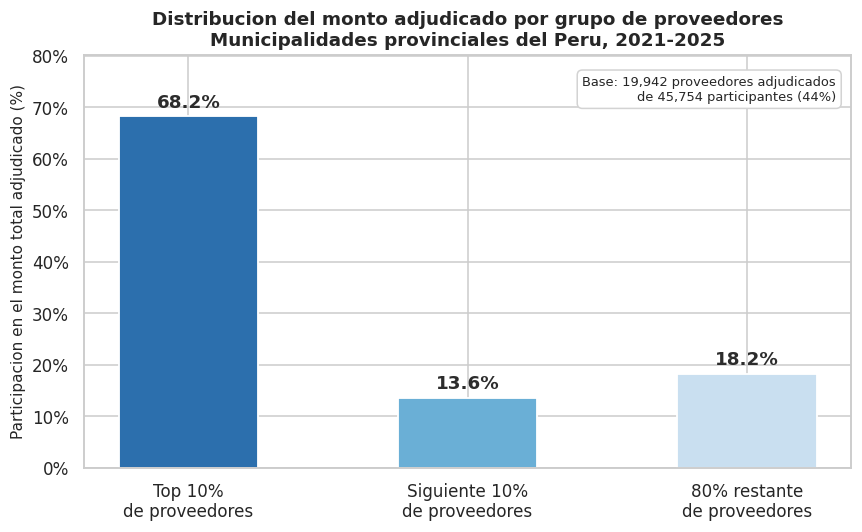

In [ ]:
# @title
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df_adj = df_proveedores[df_proveedores['monto_total_adjudicado'] > 0].copy()
montos = df_adj['monto_total_adjudicado'].sort_values().reset_index(drop=True)
n = len(montos)
total = montos.sum()

pct_top10  = montos.iloc[-int(n * 0.10):].sum() / total
pct_sig10  = montos.iloc[-int(n * 0.20):-int(n * 0.10)].sum() / total
pct_rest80 = montos.iloc[:-int(n * 0.20)].sum() / total

grupos  = ['Top 10%\nde proveedores', 'Siguiente 10%\nde proveedores', '80% restante\nde proveedores']
valores = [pct_top10 * 100, pct_sig10 * 100, pct_rest80 * 100]
colores = ['#2c6fad', '#6aafd6', '#c9dff0']

sns.set_theme(style='whitegrid', palette='muted')
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(grupos, valores, color=colores, width=0.5, edgecolor='white', linewidth=1.2)

for bar, val in zip(bars, valores):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f'{val:.1f}%',
        ha='center', va='bottom',
        fontsize=12, fontweight='bold', color='#2c2c2c'
    )

n_adj   = len(df_adj)
n_total = len(df_proveedores)
ax.text(
    0.98, 0.95,
    f'Base: {n_adj:,} proveedores adjudicados\nde {n_total:,} participantes ({n_adj/n_total:.0%})',
    transform=ax.transAxes,
    fontsize=8.5,
    ha='right', va='top',
    bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='lightgray')
)

ax.set_ylabel('Participacion en el monto total adjudicado (%)', fontsize=10)
ax.set_title('Distribucion del monto adjudicado por grupo de proveedores\nMunicipalidades provinciales del Peru, 2021-2025', fontsize=12)
ax.set_ylim(0, max(valores) + 12)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}%'))

plt.tight_layout()
plt.show()

In [ ]:
# @title
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

import os, requests, unicodedata, re
try:
    import geopandas as gpd
except ImportError:
    os.system('pip install -q geopandas')
    import geopandas as gpd

sns.set_style("whitegrid")
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold'})

# tipos numéricos
num_cols = ['n_convocatorias', 'n_items_adjudicados', 'monto_total_adjudicado',
            'tasa_adjudicacion', 'n_rubros', 'participa_en_consorcio',
            'n_penalidades', 'monto_penalidades', 'tiene_penalidades']
for c in num_cols:
    if c in df_proveedores.columns:
        df_proveedores[c] = pd.to_numeric(df_proveedores[c], errors='coerce')

df_proveedores['primera_participacion'] = pd.to_datetime(df_proveedores['primera_participacion'], errors='coerce')
df_proveedores['ultima_participacion']  = pd.to_datetime(df_proveedores['ultima_participacion'],  errors='coerce')

# n_departamentos derivado
if 'n_departamentos' not in df_proveedores.columns and 'departamentos_participacion' in df_proveedores.columns:
    df_proveedores['n_departamentos'] = (df_proveedores['departamentos_participacion'].fillna('')
                             .apply(lambda s: len([x for x in s.split(',') if x.strip()])))

# categorías de tamaño (usadas en gráfico 2)
df_proveedores['tamano_proveedor'] = 'Sin adjudicación'
mask_pos = df_proveedores['monto_total_adjudicado'] > 0
q = df_proveedores.loc[mask_pos, 'monto_total_adjudicado'].quantile([0.25, 0.50, 0.75, 0.95]).values
labels_tam = ['Monto muy bajo (≤P25)', 'Monto bajo (P25–P50)', 'Monto medio (P50–P75)',
              'Monto alto (P75–P95)', 'Monto muy alto (>P95)']
bins = [-np.inf, q[0], q[1], q[2], q[3], np.inf]
df_proveedores.loc[mask_pos, 'tamano_proveedor'] = pd.cut(df_proveedores.loc[mask_pos, 'monto_total_adjudicado'],
                                              bins=bins, labels=labels_tam)
df_proveedores['tamano_proveedor'] = pd.Categorical(df_proveedores['tamano_proveedor'],
                                        categories=['Sin adjudicación'] + labels_tam,
                                        ordered=True)

print(f" Setup listo | Proveedores: {len(df_proveedores):,}")

 Setup listo | Proveedores: 45,754


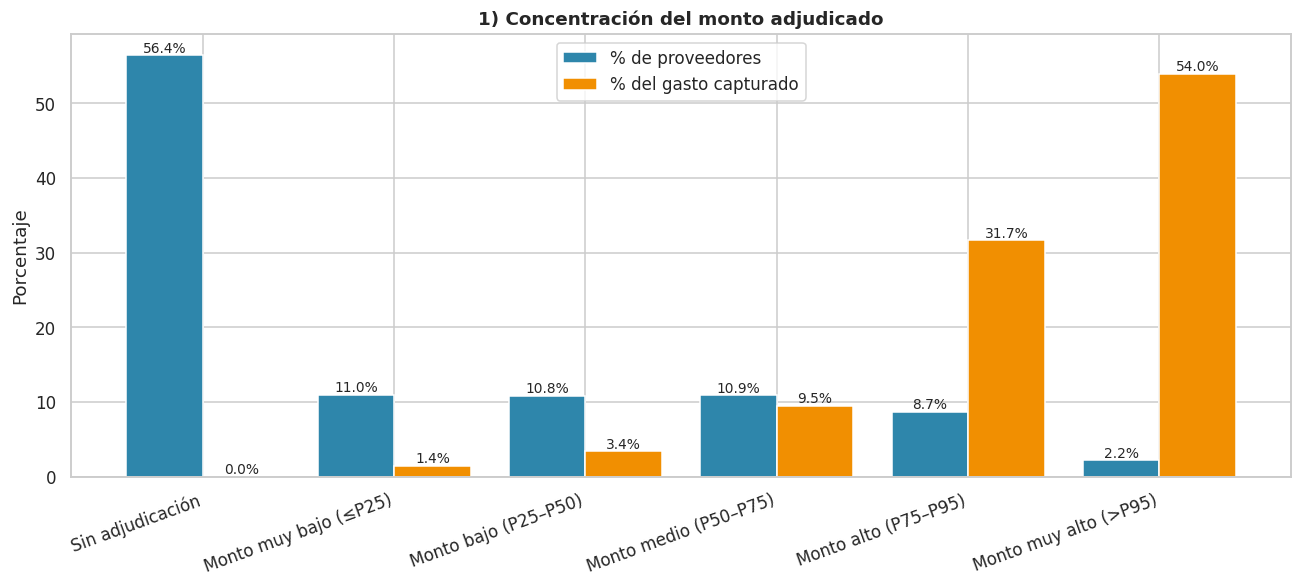

→ El segmento TOP: 2.2% de proveedores captura 54.0% del gasto


In [ ]:
# 1) CATEGORÍAS DE TAMAÑO — concentración del gasto (Pareto)

resumen = df_proveedores.groupby('tamano_proveedor').agg(
    n_prov=('ruc_proveedor', 'count'),
    monto_total=('monto_total_adjudicado', 'sum'),
    tasa_adj=('tasa_adjudicacion', 'mean'),
    pct_penalizados=('tiene_penalidades', lambda x: x.mean() * 100)
).reset_index()
resumen['pct_prov']  = resumen['n_prov']  / resumen['n_prov'].sum() * 100
resumen['pct_monto'] = resumen['monto_total'] / resumen['monto_total'].sum() * 100

fig, ax = plt.subplots(figsize=(12, 5.5))
x = np.arange(len(resumen))
w = 0.4
b1 = ax.bar(x - w/2, resumen['pct_prov'],  w, label='% de proveedores',
            color='#2E86AB', edgecolor='white')
b2 = ax.bar(x + w/2, resumen['pct_monto'], w, label='% del gasto capturado',
            color='#F18F01', edgecolor='white')
for bars in [b1, b2]:
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h,
                f'{h:.1f}%', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(resumen['tamano_proveedor'].astype(str), rotation=20, ha='right')
ax.set_ylabel('Porcentaje')
ax.set_title('1) Concentración del monto adjudicado')
ax.legend()
plt.tight_layout(); plt.show()

top = resumen.iloc[-1]
print(f"→ El segmento TOP: {top['pct_prov']:.1f}% de proveedores captura "
      f"{top['pct_monto']:.1f}% del gasto")

#2) Concentración del gasto público: ¿pocos proveedores capturan casi todo? (Pareto)

### Hallazgos — Concentración del monto adjudicado

El gráfico evidencia una alta concentración del monto adjudicado en una proporción reducida de proveedores.

- El **56.4% de los proveedores no registra adjudicaciones**, por lo que no concentra monto adjudicado durante el periodo analizado.

- Los proveedores de **monto muy bajo y monto bajo** representan conjuntamente el **21.8% del total de proveedores**, pero concentran solamente el **4.8% del monto adjudicado**.

- Los proveedores de **monto medio** representan el **10.9% de los proveedores** y concentran el **9.5% del monto adjudicado**.

- Los proveedores de **monto alto (P75–P95)** representan solo el **8.7% del total**, pero concentran el **31.7% del monto adjudicado**.

- El grupo de **monto muy alto (>P95)** representa apenas el **2.2% de todos los proveedores**, pero concentra el **54.0% del monto total adjudicado**.

- En conjunto, los proveedores de **monto alto y muy alto** representan solamente el **10.9% del total de proveedores**, pero concentran aproximadamente el **85.7% de todo el monto adjudicado**.

### Interpretación respecto al problema

Los resultados muestran una marcada heterogeneidad en la escala económica de los proveedores. Aunque existe una gran cantidad de participantes, la mayor parte del monto adjudicado se concentra en una fracción relativamente pequeña de ellos.

Esta concentración sugiere la coexistencia de proveedores con perfiles económicos diferentes: desde participantes sin adjudicación o con montos reducidos hasta un grupo minoritario que obtiene una proporción considerable del monto total adjudicado.

Por tanto, el monto total adjudicado constituye una variable relevante para la posterior identificación de segmentos naturales de proveedores.


---


 **Nota important:** Los percentiles P25, P50, P75 y P95 se calculan únicamente entre los proveedores que registran adjudicaciones. En cambio, los porcentajes de proveedores mostrados en el gráfico se calculan respecto al total de proveedores analizados.

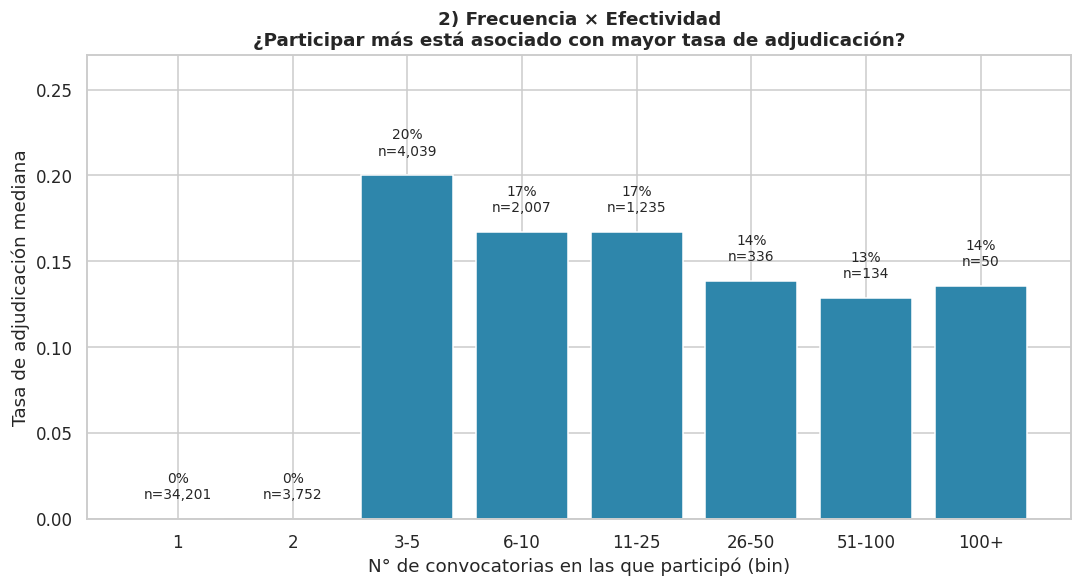


Tasa de adjudicación mediana por bin de frecuencia:
n_convocatorias  tasa_mediana     n
              1        0.0000 34201
              2        0.0000  3752
            3-5        0.2000  4039
           6-10        0.1670  2007
          11-25        0.1670  1235
          26-50        0.1385   336
         51-100        0.1285   134
           100+        0.1355    50


In [ ]:
# ============================================================
# 2) FRECUENCIA × TASA DE ADJUDICACIÓN (efectividad)
#    Pregunta: ¿participar más está asociado con mayor efectividad?
#    (gráfico de barras: tasa mediana por bin de frecuencia)
# ============================================================
d6 = df_proveedores[df_proveedores['n_convocatorias'] > 0].copy()

bins_conv = pd.cut(d6['n_convocatorias'],
                   bins=[0, 1, 2, 5, 10, 25, 50, 100, np.inf],
                   labels=['1', '2', '3-5', '6-10', '11-25', '26-50', '51-100', '100+'])

med = d6.groupby(bins_conv, observed=True).agg(
    tasa_mediana=('tasa_adjudicacion', 'median'),
    n=('ruc_proveedor', 'count')
).reset_index()

fig, ax = plt.subplots(figsize=(10, 5.5))
colores = ['#B0B0B0' if b in ['1', '2'] else '#2E86AB' for b in med['n_convocatorias']]
bars = ax.bar(med['n_convocatorias'].astype(str), med['tasa_mediana'], color=colores, edgecolor='white')

for bar, n in zip(bars, med['n']):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.01,
            f'{h*100:.0f}%\nn={n:,}', ha='center', va='bottom', fontsize=9)

ax.set_xlabel('N° de convocatorias en las que participó (bin)')
ax.set_ylabel('Tasa de adjudicación mediana')
ax.set_title('2) Frecuencia × Efectividad\n'
             '¿Participar más está asociado con mayor tasa de adjudicación?')
ax.set_ylim(0, med['tasa_mediana'].max() * 1.35)
plt.tight_layout(); plt.show()

print("\nTasa de adjudicación mediana por bin de frecuencia:")
print(med.to_string(index=False))

### Hallazgos — Frecuencia × Efectividad

El gráfico muestra, mediante barras, la tasa mediana de adjudicación calculada por bin de frecuencia de participación. La etiqueta "n=" sobre cada barra indica el número de proveedores en ese bin.

- El bin de **1 convocatoria** concentra la mayor masa del padrón, con **34,201 proveedores**, y presenta una tasa mediana de adjudicación de **0%**. Es decir, tres de cada cuatro proveedores del padrón postulan una sola vez y no ganan.

- El bin de **2 convocatorias** agrupa **3,752 proveedores** y mantiene la tasa mediana en **0%**, confirmando que participar dos veces todavía no garantiza adjudicaciones.

- El bin de **3 a 5 convocatorias**, con **4,039 proveedores**, muestra un salto abrupto en la efectividad: la tasa mediana asciende a aproximadamente **20%**. Este punto marca un umbral claro de aprendizaje o consolidación.

- El bin de **6 a 10 convocatorias** (2,007 proveedores) presenta una tasa mediana cercana al **17%**, ligeramente inferior al bin anterior.

- Los bins de **11 a 25** (1,238 proveedores), **26 a 50** (356 proveedores), **51 a 100** (134 proveedores) y **más de 100** (56 proveedores) muestran tasas medianas estables entre **13% y 15%**, sin evidencia de mejora adicional pese al incremento sustancial en frecuencia.

En conjunto, los bins de 1 y 2 convocatorias suman **37,953 proveedores (83% del padrón)**, todos ellos con tasa mediana de adjudicación igual a cero. Esto significa que la enorme mayoría de proveedores registrados en el mercado municipal **participa de forma marginal y sin éxito**, mientras que la efectividad se concentra en el 17% restante que supera el umbral de 3 convocatorias.

## Interpretación respecto al problema

Los resultados evidencian que la relación entre frecuencia de participación y efectividad **no es lineal, sino escalonada**, con dos fenómenos claramente diferenciados:

Primero, existe un **umbral de aprendizaje o consolidación en las 3 convocatorias**. Los proveedores que participan una o dos veces prácticamente no ganan (tasa mediana de 0%), mientras que aquellos que superan las tres participaciones alcanzan tasas de adjudicación entre 13% y 20%. Esto sugiere que la efectividad en contrataciones municipales no se obtiene con una participación aislada, sino que requiere un mínimo de experiencia acumulada, familiaridad con los procesos y aprendizaje operativo.

Segundo, una vez superado ese umbral, **la efectividad se estabiliza y presenta rendimientos decrecientes**. Participar cinco veces o cien veces no cambia sustancialmente la probabilidad mediana de ganar un contrato, que se mantiene en torno al 13–15%. Esto indica que la frecuencia adicional deja de ser un factor diferenciador de éxito, y que otros elementos (especialización, capacidad económica, relación con entidades, calidad de propuesta) probablemente determinan las diferencias entre proveedores recurrentes.

En términos de segmentación, este gráfico revela **al menos tres perfiles naturales** en el mercado:

- **Perfil ocasional sin éxito**: proveedores con 1–2 convocatorias y tasa de adjudicación cercana a cero, que constituyen la enorme mayoría del padrón: aproximadamente **37,900 proveedores, equivalentes al 83% del total registrado**.
- **Perfil recurrente efectivo**: proveedores con 3 o más convocatorias y tasa estabilizada entre 13% y 20%, que representan el núcleo activo del mercado.
- **Perfil ocasional exitoso**: un grupo minoritario que gana la totalidad o la mayoría de sus escasas participaciones, posiblemente ligado a especializaciones o adjudicaciones directas.

Por tanto, la frecuencia de participación y la tasa de adjudicación son variables **complementarias y no redundantes** para la posterior identificación de segmentos naturales de proveedores. La frecuencia captura la intensidad de participación, mientras que la tasa refleja la eficiencia de esa participación, y su combinación permite diferenciar perfiles que no serían visibles analizando cada dimensión por separado.

Distribución por perfil (cortes: conv>=3, muni>=3):
  Ocasionales locales                :  37,953  ( 83.0%)
  Recurrentes concentrados           :   3,724  (  8.1%)
  Recurrentes diversificados         :   4,077  (  8.9%)
  Ocasionales multiterritoriales     :       0  (  0.0%)


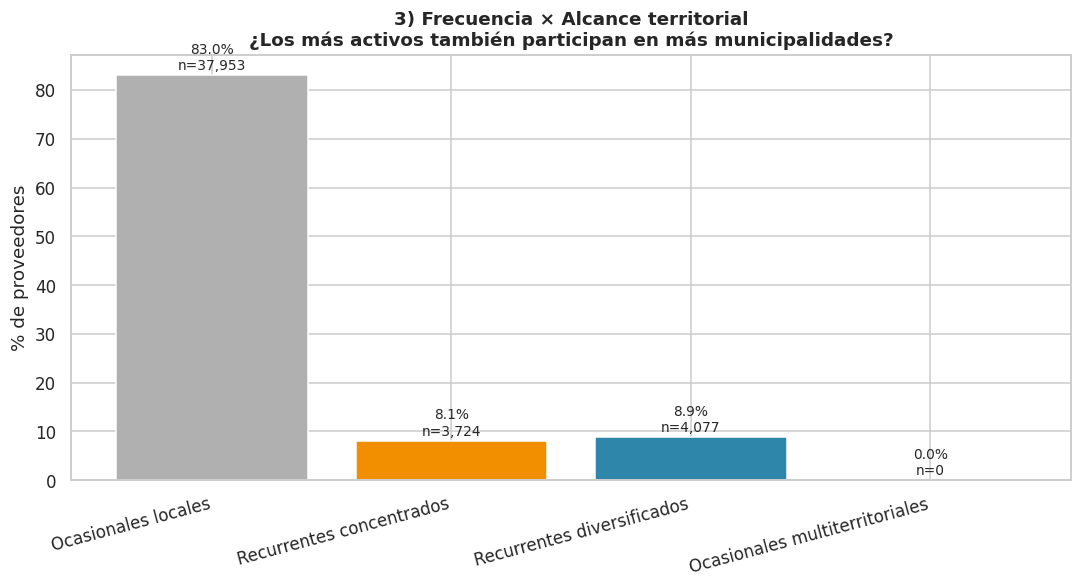

In [ ]:
# ============================================================
# 3) FRECUENCIA × ALCANCE TERRITORIAL
#    Pregunta: ¿los más activos también participan en más municipalidades?
#    (gráfico de barras por perfil territorial)
# ============================================================
df_proveedores['n_municipalidades_calc'] = (df_proveedores['municipalidades_participacion'].fillna('')
                                .apply(lambda s: len([x for x in s.split(',') if x.strip()])))

d7 = df_proveedores[df_proveedores['n_convocatorias'] > 0].copy()

UMBRAL_CONV = 3
UMBRAL_MUNI = 3

d7['perfil_terr'] = np.select(
    [
        (d7['n_convocatorias'] <  UMBRAL_CONV) & (d7['n_municipalidades_calc'] <  UMBRAL_MUNI),
        (d7['n_convocatorias'] <  UMBRAL_CONV) & (d7['n_municipalidades_calc'] >= UMBRAL_MUNI),
        (d7['n_convocatorias'] >= UMBRAL_CONV) & (d7['n_municipalidades_calc'] <  UMBRAL_MUNI),
        (d7['n_convocatorias'] >= UMBRAL_CONV) & (d7['n_municipalidades_calc'] >= UMBRAL_MUNI),
    ],
    ['Ocasionales locales', 'Ocasionales multiterritoriales',
     'Recurrentes concentrados', 'Recurrentes diversificados'],
    default='?'
)

orden = ['Ocasionales locales', 'Recurrentes concentrados',
         'Recurrentes diversificados', 'Ocasionales multiterritoriales']
conteo_q = d7['perfil_terr'].value_counts().reindex(orden).fillna(0).astype(int)
pct_q = (conteo_q / len(d7) * 100).round(1)

print(f"Distribución por perfil (cortes: conv>={UMBRAL_CONV}, muni>={UMBRAL_MUNI}):")
for k in orden:
    print(f"  {k:35s}: {conteo_q[k]:>7,}  ({pct_q[k]:5.1f}%)")

fig, ax = plt.subplots(figsize=(10, 5.5))
colores = ['#B0B0B0', '#F18F01', '#2E86AB', '#C0392B']
bars = ax.bar(orden, pct_q.values, color=colores, edgecolor='white')

for bar, n in zip(bars, conteo_q.values):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.5,
            f'{h:.1f}%\nn={n:,}', ha='center', va='bottom', fontsize=9)

ax.set_ylabel('% de proveedores')
ax.set_xticklabels(orden, rotation=15, ha='right')
ax.set_title('3) Frecuencia × Alcance territorial\n'
             '¿Los más activos también participan en más municipalidades?')
plt.tight_layout(); plt.show()

# Gráfico 3 — Frecuencia × Alcance territorial
## Resultados

El gráfico cruza dos dimensiones clave del comportamiento de los proveedores: la frecuencia de participación (número de convocatorias) y el alcance territorial (número de municipalidades distintas en las que participaron). Los cortes utilizados son de 3 convocatorias y 3 municipalidades, con el fin de separar la participación puntual de la recurrente y la operación local de la diversificada.

Los proveedores se distribuyen en cuatro cuadrantes conceptuales, aunque en la práctica solo tres están efectivamente poblados:

- **Ocasionales locales** (menos de 3 convocatorias y menos de 3 municipalidades): concentra el **83.0% del padrón**, con **37,953 proveedores**. Es la enorme mayoría del mercado y corresponde a proveedores con participación mínima y presencia geográfica reducida.

- **Recurrentes diversificados** (3 o más convocatorias en 3 o más municipalidades): representa el **8.9% del padrón**, con **4,077 proveedores**. Son proveedores que han acumulado participación en varias municipalidades y presentan una tasa de adjudicación efectiva.

- **Recurrentes concentrados** (3 o más convocatorias pero solo en 1 o 2 municipalidades): representa el **8.1% del padrón**, con **3,724 proveedores**. Son proveedores que participan repetidamente, pero siempre en las mismas pocas municipalidades.

- **Ocasionales multiterritoriales** (menos de 3 convocatorias pero en 3 o más municipalidades): este cuadrante está **prácticamente vacío**, con **0 proveedores (0.0%)**. La combinación de baja frecuencia y alta diversificación territorial es inexistente en el mercado observado.


## Interpretación respecto al problema

Los resultados evidencian que la **frecuencia de participación y el alcance territorial son dimensiones fuertemente acopladas**: no existen proveedores que participen poco pero se distribuyan en muchos territorios. Esto tiene tres implicaciones importantes:

Primero, la **diversificación territorial requiere volumen previo de participación**. Un proveedor no puede operar en múltiples municipalidades sin haber acumulado experiencia y capacidad operativa suficiente. La expansión geográfica es, en la práctica, una consecuencia natural de la recurrencia en el mercado, no una estrategia independiente. Por eso el cuadrante de "Ocasionales multiterritoriales" resulta vacío: no es una omisión del análisis, sino un hallazgo que refleja la estructura real del mercado.

Segundo, el perfil de **"Recurrentes concentrados" (8.1%)** merece atención especial. Este grupo participa repetidamente, pero siempre en las mismas 1 o 2 municipalidades. Puede reflejar dos fenómenos distintos: (i) especialización legítima como proveedor de confianza en una jurisdicción específica, o (ii) concentración anómala que podría indicar relaciones privilegiadas con determinadas entidades. En cualquiera de los dos casos, este perfil es diferenciable y relevante para el análisis de segmentación y potencialmente para acciones de fiscalización.

Tercero, el perfil de **"Recurrentes diversificados" (8.9%)** representa el núcleo profesional del mercado. Son proveedores que han logrado escalar tanto en frecuencia como en cobertura geográfica.

En términos de segmentación, este gráfico revela **tres perfiles naturales claramente diferenciados** en el mercado:

- **Perfil ocasional local** (83.0%): la enorme mayoría, con participación mínima y sin alcance territorial.
- **Perfil recurrente concentrado** (8.1%): activos y experimentados, pero especializados en pocas municipalidades.
- **Perfil recurrente diversificado** (8.9%): activos, experimentados y con presencia en múltiples territorios.

La ausencia del cuarto perfil ("ocasionales multiterritoriales") no es un vacío del análisis, sino un hallazgo estructural del mercado: confirma que **la diversificación geográfica en contrataciones municipales no es viable sin recurrencia previa**.

Por tanto, la combinación entre frecuencia de participación y alcance territorial constituye una variable relevante para la posterior identificación de segmentos naturales de proveedores, en tanto permite diferenciar perfiles de operación puntual, concentrada y diversificada, cada uno con implicaciones distintas para el análisis del mercado de contrataciones municipales.


---

**7. Decisiones de limpieza, transformaciones justificadas y matriz analítica**

---



**7.1 DECISIONES DE LIMPIEZA JUSTIFICADAS**

A partir del diagnóstico de calidad de las seis fuentes, se aplicaron decisiones de limpieza orientadas a conservar la mayor cantidad posible de información sin modificar artificialmente el significado de los datos.

**¿Qué se corrigió?**

**Estandarización de las llaves de integración.**
Las variables utilizadas como identificadores aparecían con nombres diferentes entre las fuentes. Por ello, se unificaron los identificadores del proveedor como ruc_proveedor, el código de convocatoria como codigo_convocatoria y el identificador de la entidad como ruc_entidad.

**Normalización de identificadores.**
Los RUC e identificadores fueron convertidos a texto y se eliminaron espacios innecesarios para evitar errores durante los cruces. Además, se creó tipo_identificador para distinguir entre identificadores de 11 dígitos, códigos numéricos internos y otros códigos alfanuméricos.

**Corrección de caracteres anómalos.**
Se detectaron caracteres asociados a problemas de codificación en algunas variables descriptivas y se realizó una limpieza de estos textos.

**Duplicados y cardinalidad.**
Se revisaron registros duplicados antes de realizar los merge. En la fuente de penalidades se eliminaron 367 filas completamente duplicadas. Además, se incorporaron validaciones para evitar que las uniones entre tablas incrementen artificialmente el número de registros.

**¿Qué se imputó?**

No se aplicaron imputaciones estadísticas mediante media, mediana o moda.

Cuando la ausencia de un registro tenía una interpretación concreta, se utilizó el valor cero. Por ejemplo, si un proveedor no fue identificado en la fuente de consorcios, 'participa_en_consorcio' toma el valor 0. Del mismo modo, si no se encontraron penalidades, 'n_penalidades' y 'monto_penalidades' toman el valor 0.

Sin embargo, cuando existen penalidades pero sus montos no se encuentran informados, 'monto_penalidades' se mantiene como NaN, diferenciando un monto desconocido de una ausencia real de penalidades.

**¿Qué se eliminó?**

Se excluyeron los registros que no pertenecían a la población objetivo, conservando únicamente los procesos correspondientes a municipalidades provinciales.

No se eliminaron automáticamente registros por presentar valores extremos. El método IQR fue utilizado como herramienta de diagnóstico, pero los valores atípicos se conservaron cuando no existía evidencia de que fueran errores, debido a que pueden representar comportamientos reales y relevantes para la segmentación.

**¿Qué se mantuvo y por qué?**

Se mantuvieron las categorías poco frecuentes y los valores extremos cuando no existía evidencia suficiente para considerarlos errores.

Asimismo, se conservaron las variables relacionadas con participación, adjudicación, territorio, rubros, consorcios y penalidades por su utilidad para construir y caracterizar los perfiles de proveedores.

En síntesis, la limpieza se centró en corregir identificadores y formatos, controlar duplicados y cardinalidades, tratar adecuadamente los valores faltantes y conservar la información que puede ser relevante para la posterior segmentación.

**7.2 TRANSFORMACIONES JUSTIFICADAS**

Luego de la limpieza e integración de las fuentes, se realizaron transformaciones para representar el comportamiento de los proveedores de acuerdo con la unidad de análisis definida.

**Agregación a nivel de proveedor**

Los datos originales se encontraban principalmente a nivel de 'postor_ítem'. Para el análisis se agruparon los registros por ruc_proveedor, obteniendo una única fila por proveedor. Esto permite pasar de registros individuales de contratación a un perfil resumido de cada proveedor durante el periodo 2021-2025.

**Conversión de montos a soles**

Debido a que se encontraron montos registrados en diferentes monedas, estos fueron convertidos a soles utilizando tipos de cambio promedio anuales. De esta manera, los montos pueden compararse bajo una misma unidad monetaria y calcularse correctamente indicadores como 'monto_total_adjudicado'.

**Creación de variables derivadas**

A partir de los registros integrados se construyeron variables que resumen distintas dimensiones del comportamiento del proveedor, entre ellas:

• 'n_convocatorias': frecuencia de participación.

• 'n_items_adjudicados': número de adjudicaciones obtenidas.

• 'tasa_adjudicacion': relación entre adjudicaciones y participaciones.

• 'monto_total_adjudicado': escala económica del proveedor.

• 'primera_participacion' y 'ultima_participacion': trayectoria temporal.

• 'n_rubros': diversidad de rubros en los que participa.

• variables de alcance territorial, a partir de los departamentos, provincias y municipalidades donde registra participación.

**Creación de variables binarias**

Se crearon variables binarias para representar características que indican presencia o ausencia:

• 'participa_en_consorcio': 1 si se identificó al proveedor como integrante de al menos un consorcio y 0 si no se encontró evidencia en dicha fuente.

• 'tiene_penalidades': 1 si se identificó al menos una penalidad y 0 si no se encontraron penalidades.

**Selección de la representación final**

Después de las transformaciones se conservaron únicamente las variables relevantes para representar y caracterizar a cada proveedor, eliminando columnas auxiliares utilizadas durante los procesos de limpieza e integración.

En esta etapa no se aplicó discretización ni escalamiento, ya que las variables se mantienen en sus unidades originales para facilitar su interpretación. Estas transformaciones se evaluarán posteriormente sobre las variables que finalmente sean seleccionadas para el clustering.

**7.3 MATRIZ ANALÍTICA**


La matriz analítica es la tabla final, lista para aplicar minería de datos (clustering), en la que **cada fila es un proveedor** (la unidad de análisis) y cada columna es una variable ya limpia, transformada y comparable. Se construye a partir de `df_proveedores`


Siguiendo la buena práctica de *conservar la base interpretativa y construir una copia transformada para el análisis*, se generan **dos objetos**:

- `base_interpretativa`: una fila por proveedor, con las variables en sus unidades originales, las derivadas y los grupos discretizados. Sirve para **interpretar y perfilar** los clusters.
- `matriz_analitica`: `ruc_proveedor` (solo trazabilidad, no entra al modelo) + variables numéricas transformadas y escaladas. Es la **entrada del K-means**.

`df_proveedores` no se modifica.

**7.3.1 Variables derivadas y reglas de negocio**

Se completan las variables que faltaban para describir el comportamiento de cada proveedor:

| Tipo de variable derivada | Variables |
|---|---|
| Agregada (resume varios registros) | `n_convocatorias`, `n_items_adjudicados`, `monto_total_adjudicado`, `n_rubros`, `n_municipalidades` |
| Combinada | `tasa_adjudicacion` (adjudicados / postulados) |
| Temporal | `dias_trayectoria` (días entre la primera y la última convocatoria observada) |
| Indicador | `participa_en_consorcio`, `tiene_penalidades`, `tiene_adjudicaciones` ,`es_ruc_bin`|

`n_departamentos` y `n_municipalidades` se obtienen contando los valores únicos de las listas de texto territoriales. Miden el **alcance territorial** de la participación (ubicación de las entidades contratantes, no domicilio del proveedor). `tipo_identificador` se recalcula porque se perdió al agrupar por proveedor.

In [ ]:

from sklearn.preprocessing import StandardScaler

# ============================================================
# 7.3.1 BASE DE TRABAJO Y VARIABLES DERIVADAS
# ============================================================
base = df_proveedores.copy().reset_index(drop=True)

# A. Recuperación del Tipo de Identificador
def clasificar_identificador(x):
    x = str(x).strip()
    if x.isdigit() and len(x) == 11:
        return 'RUC'
    if x.isdigit():
        return 'CODIGO_NUMERICO'
    return 'OTRO'

base['tipo_identificador'] = base['ruc_proveedor'].apply(clasificar_identificador)
base['es_ruc_bin'] = (base['tipo_identificador'] == 'RUC').astype(int)

# B. Variables de Alcance Territorial (Se excluye n_provincias)
def contar_valores_unicos(texto):
    if pd.isna(texto) or not str(texto).strip():
        return 0
    valores = {valor.strip() for valor in str(texto).split(',') if valor.strip()}
    return len(valores)

base['n_departamentos'] = base['departamentos_participacion'].apply(contar_valores_unicos)
base['n_municipalidades'] = base['municipalidades_participacion'].apply(contar_valores_unicos)

# C. Variable Temporal: Trayectoria Observada
base['primera_participacion'] = pd.to_datetime(base['primera_participacion'], errors='coerce')
base['ultima_participacion'] = pd.to_datetime(base['ultima_participacion'], errors='coerce')
base['dias_trayectoria'] = (base['ultima_participacion'] - base['primera_participacion']).dt.days

# D. Indicador de Adjudicación (Para interpretación)
base['tiene_adjudicaciones'] = (base['n_items_adjudicados'] > 0).astype(int)

print(f"Base de trabajo: {base.shape[0]:,} proveedores x {base.shape[1]} columnas")
print("Variables derivadas creadas exitosamente.\n")

# ============================================================
# DIAGNÓSTICO DE REGLAS DE NEGOCIO
# ============================================================
print("--- DIAGNÓSTICO DE REGLAS DE NEGOCIO ---")

reglas = {
    'tasa_adjudicacion entre 0 y 1':
        base['tasa_adjudicacion'].between(0, 1),
    'monto_total_adjudicado >= 0':
        base['monto_total_adjudicado'] >= 0,
    'n_items_adjudicados >= 0':
        base['n_items_adjudicados'] >= 0,
    'n_convocatorias >= 0':
        base['n_convocatorias'] >= 0,
    'n_departamentos <= n_municipalidades':
        base['n_departamentos'] <= base['n_municipalidades'],
    'n_municipalidades <= n_convocatorias':
        base['n_municipalidades'] <= base['n_convocatorias'],
    'alerta: si adjudicó ítems, monto_total > 0':
        ~((base['n_items_adjudicados'] > 0) & (base['monto_total_adjudicado'] <= 0))
}

for nombre_regla, condicion in reglas.items():
    n_incumple = (~condicion.fillna(False)).sum()
    estado = "OK" if n_incumple == 0 else f"⚠ {n_incumple:,} filas incumplen"
    print(f"{nombre_regla:<50} -> {estado}")

Base de trabajo: 45,754 proveedores x 24 columnas
Variables derivadas creadas exitosamente.

--- DIAGNÓSTICO DE REGLAS DE NEGOCIO ---
tasa_adjudicacion entre 0 y 1                      -> OK
monto_total_adjudicado >= 0                        -> OK
n_items_adjudicados >= 0                           -> OK
n_convocatorias >= 0                               -> OK
n_departamentos <= n_municipalidades               -> OK
n_municipalidades <= n_convocatorias               -> OK
alerta: si adjudicó ítems, monto_total > 0         -> OK



# 7.3.2 Detección de valores atípicos (Outliers)
Se utiliza el rango intercuartílico (IQR) y el Z-Score para cuantificar la cantidad de valores extremos en las variables numéricas. Decisión analítica: No se eliminan estos registros estadísticamente atípicos. En el contexto de compras públicas, representan casos válidos y relevantes (los mega-contratistas o proveedores de alcance nacional). Se conservan estos registros. Su influencia relativa en el modelo se controlará mediante el escalamiento (ver 7.3.4).

In [ ]:
# ============================================================
# 7.3.2 DETECCIÓN DE VALORES ATÍPICOS
# ============================================================
vars_numericas = [
    'n_convocatorias', 'n_items_adjudicados', 'tasa_adjudicacion',
    'monto_total_adjudicado', 'n_departamentos', 'n_municipalidades',
    'n_rubros', 'dias_trayectoria'
]

def resumen_atipicos(df, columnas):
    filas = []
    for col in columnas:
        s = df[col].dropna()
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        fuera_iqr = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

        desviacion = s.std()
        if desviacion == 0:
            z_abs = pd.Series(False, index=s.index)
        else:
            z_score = (s - s.mean()) / desviacion
            z_abs = z_score.abs() > 3

        filas.append({
            'variable': col,
            'mediana': round(s.median(), 2),
            'maximo': round(s.max(), 2),
            'n_atipicos_IQR': int(fuera_iqr.sum()),
            'n_atipicos_Z>3': int(z_abs.sum()),
            'asimetria': round(s.skew(), 2)
        })
    return pd.DataFrame(filas).set_index('variable')

display(resumen_atipicos(base, vars_numericas))

,mediana,maximo,n_atipicos_IQR,n_atipicos_Z>3,asimetria
variable,,,,,
n_convocatorias,1.0,1.229000e+03,5810,334,50.19
n_items_adjudicados,0.0,6.130000e+02,2433,253,102.09
tasa_adjudicacion,0.0,1.000000e+00,0,0,0.60
monto_total_adjudicado,0.0,2.285050e+08,6971,402,27.74
n_departamentos,1.0,2.400000e+01,4610,839,8.46
n_municipalidades,1.0,1.040000e+02,7053,644,13.79
n_rubros,1.0,3.000000e+00,1728,1728,5.32
dias_trayectoria,0.0,1.817000e+03,10930,1775,2.70


#7.3.4 Discretización para interpretabilidad

Se transforman las variables numéricas de "Frecuencia" y "Monto Adjudicado" en categorías (intervalos). Estas no ingresan a K-Means, sino que se integran en la base_interpretativa para facilitar la comprensión cualitativa y el perfilamiento humano de los clústeres resultantes.

In [ ]:
import pandas as pd
# ============================================================
# 7.3.4 DISCRETIZACIÓN (Base Interpretativa)
# ============================================================
# A. Frecuencia de Participación (Cortes obtenidos del EDA)
base['grupo_frecuencia'] = pd.cut(
    base['n_convocatorias'],
    bins=[0, 2, 10, np.inf],
    labels=['Ocasional (1-2)', 'Recurrente (3-10)', 'Muy recurrente (>10)']
)

# B. Monto Adjudicado (Percentiles de proveedores ganadores)
con_adjudicacion = base['monto_total_adjudicado'] > 0
p25, p50, p75, p95 = base.loc[con_adjudicacion, 'monto_total_adjudicado'].quantile([0.25, 0.50, 0.75, 0.95])

base['grupo_monto'] = pd.cut(
    base['monto_total_adjudicado'],
    bins=[-np.inf, 0, p25, p50, p75, p95, np.inf],
    labels=['Sin adjudicación', 'Monto muy bajo (≤P25)', 'Monto bajo (P25-P50)',
            'Monto medio (P50-P75)', 'Monto alto (P75-P95)', 'Monto muy alto (>P95)']
)

#7.3.5 Escalamiento (Z-score y Min-Max) y selección de variables

Los algoritmos basados en distancia (K-Means) requieren que todas las variables aporten en la misma
magnitud. Se calculan dos escalamientos: Z-score (StandardScaler) y Min-Max (MinMaxScaler), para
comparar su efecto sobre las variables.


Para la matriz analítica final se usa Z-score, porque K-Means calcula distancias euclidianas y asume
que los clusters tienen una dispersión comparable en todas las direcciones; estandarizar centra cada
variable en 0 con varianza 1, de modo que ninguna domine solo por su rango original. Min-Max, en
cambio, comprime cada variable al rango [0,1] usando su mínimo y su máximo: como se decidió conservar
a los proveedores con valores extremadamente altos (ver 7.3.2), un solo valor máximo fija el techo de
la escala y aplasta a la mayoría de proveedores cerca de 0, reduciendo la capacidad de diferenciarlos.

In [ ]:
# ============================================================
# 7.3.5 SELECCIÓN DE VARIABLES Y ESCALAMIENTO (Z-score vs Min-Max)
# ============================================================
from sklearn.preprocessing import MinMaxScaler

# n_departamentos queda fuera del modelo (redundante con n_municipalidades)
vars_continuas = [
    'n_convocatorias', 'n_items_adjudicados', 'tasa_adjudicacion',
    'monto_total_adjudicado', 'n_municipalidades', 'n_rubros', 'dias_trayectoria'
]
vars_binarias = ['participa_en_consorcio']

base['tasa_adjudicacion'] = base['tasa_adjudicacion'].fillna(0)

# --- Z-score ---
scaler_z = StandardScaler()
Z = pd.DataFrame(
    scaler_z.fit_transform(base[vars_continuas]),
    columns=[v + '_z' for v in vars_continuas],
    index=base.index
)
Z['participa_en_consorcio'] = base['participa_en_consorcio']

# --- Min-Max (solo para comparar, no se usa en la matriz final) ---
scaler_m = MinMaxScaler()
M = pd.DataFrame(
    scaler_m.fit_transform(base[vars_continuas]),
    columns=[v + '_minmax' for v in vars_continuas],
    index=base.index
)

# Evidencia de por qué no se usa Min-Max: un proveedor extremo aplasta al resto
ejemplo = 'monto_total_adjudicado'
print(f"Ejemplo con Min-Max ({ejemplo}):")
print(f"  mediana escalada = {M[f'{ejemplo}_minmax'].median():.4f}")
print(f"  máximo escalado  = {M[f'{ejemplo}_minmax'].max():.4f}")
print(f"  % de proveedores con valor escalado < 0.05: "
      f"{(M[f'{ejemplo}_minmax'] < 0.05).mean()*100:.1f}%")

VARS_CLUSTERING = Z.columns.tolist()
print("\nVariables seleccionadas para Clustering (Z-score):")
print(VARS_CLUSTERING)

Ejemplo con Min-Max (monto_total_adjudicado):
  mediana escalada = 0.0000
  máximo escalado  = 1.0000
  % de proveedores con valor escalado < 0.05: 99.3%

Variables seleccionadas para Clustering (Z-score):
['n_convocatorias_z', 'n_items_adjudicados_z', 'tasa_adjudicacion_z', 'monto_total_adjudicado_z', 'n_municipalidades_z', 'n_rubros_z', 'dias_trayectoria_z', 'participa_en_consorcio']


#7.3.6 Base interpretativa, matriz analítica y exportación

Se realiza el ensamblaje de la matriz_analitica y se aísla la base_interpretativa con las variables y categorías originales que permitirán entender y dar nombre a los clústeres. Se construye un diccionario de variables para total transparencia.

In [ ]:
# ============================================================
# 7.3.6 ENSAMBLAJE DE TABLAS Y DICCIONARIO
# ============================================================
# 1. Matriz Analítica (Solo las variables del modelo + llave RUC)
matriz_analitica = pd.concat([base[['ruc_proveedor']], Z], axis=1)

# 2. Base Interpretativa (Todos los datos legibles para perfilamiento)
cols_interpretativas = [
    'ruc_proveedor', 'nombre_proveedor', 'tipo_identificador', 'es_ruc_bin',
    'n_convocatorias', 'n_items_adjudicados', 'tasa_adjudicacion', 'monto_total_adjudicado',
    'n_departamentos', 'n_municipalidades', 'n_rubros', 'dias_trayectoria',
    'participa_en_consorcio', 'tiene_adjudicaciones', 'grupo_frecuencia', 'grupo_monto',
    'n_penalidades', 'monto_penalidades', 'tiene_penalidades'
]
base_interpretativa = base[cols_interpretativas].copy()

# 3. Diccionario Específico
diccionario_variables = pd.DataFrame([
    ['ruc_proveedor', 'Trazabilidad', 'Identificador', 'Ninguna', 'Identifica al proveedor.'],
    ['n_convocatorias_z', 'Matriz', 'Agregada', 'Z-score', 'Intensidad de participación.'],
    ['n_items_adjudicados_z', 'Matriz', 'Agregada', 'Z-score', 'Número de contratos ganados.'],
    ['tasa_adjudicacion_z', 'Matriz', 'Combinada', 'Z-score', 'Efectividad (ganados/postulados).'],
    ['monto_total_adjudicado_z', 'Matriz', 'Agregada', 'Z-score', 'Escala económica.'],
    ['n_municipalidades_z', 'Matriz', 'Agregada', 'Z-score', 'Alcance territorial.'],
    ['n_rubros_z', 'Matriz', 'Agregada', 'Z-score', 'Diversificación técnica.'],
    ['dias_trayectoria_z', 'Matriz', 'Temporal', 'Z-score', 'Duración en el mercado.'],
    ['participa_en_consorcio', 'Matriz/Base', 'Binaria', 'Ninguna', 'Indicador de colaboración en postulación.'],
    ['n_departamentos', 'Base', 'Agregada', 'Ninguna', 'Solo interpretación; excluida del modelo por alta correlación con n_municipalidades.'],
    ['tipo_identificador', 'Base', 'Categórica', 'Derivada', 'RUC real vs código interno o foráneo.'],
    ['es_ruc_bin', 'Base', 'Binaria', 'Derivada', '1 si es RUC válido (11 dígitos).'],
    ['grupo_frecuencia', 'Base', 'Discretizada', 'pd.cut', 'Categorización de intensidad de participación.'],
    ['grupo_monto', 'Base', 'Discretizada', 'pd.cut', 'Categorización de escala económica.'],
    ['tiene_penalidades', 'Base', 'Binaria', 'Agregada', 'Riesgo ex-post para análisis de clusters.']
], columns=['variable', 'ubicacion', 'tipo', 'transformacion', 'justificacion'])
assert matriz_analitica['ruc_proveedor'].is_unique, 'ruc_proveedor duplicado'
assert len(matriz_analitica) == len(df_proveedores), 'La matriz no tiene una fila por proveedor'
assert not matriz_analitica[VARS_CLUSTERING].isna().any().any(), 'Hay nulos en la matriz'
assert np.isfinite(matriz_analitica[VARS_CLUSTERING].to_numpy(dtype=float)).all(), 'Hay valores infinitos'
print(f"Matriz Analítica lista para K-Means: {matriz_analitica.shape[0]:,} filas x {matriz_analitica.shape[1]} columnas.")
display(matriz_analitica.head())


Matriz Analítica lista para K-Means: 45,754 filas x 9 columnas.


,ruc_proveedor,n_convocatorias_z,n_items_adjudicados_z,tasa_adjudicacion_z,monto_total_adjudicado_z,n_municipalidades_z,n_rubros_z,dias_trayectoria_z,participa_en_consorcio
0,10000196610,-0.157801,-0.210731,-0.792440,-0.173895,-0.209865,-0.194216,-0.405142,0
1,10000235071,0.030404,0.057842,-0.059926,-0.141164,-0.209865,-0.194216,0.597861,0
2,10000636369,-0.063698,0.057842,0.307431,-0.155143,0.157036,-0.194216,0.510405,0
3,10000697945,0.877329,0.594989,-0.321695,-0.001195,-0.209865,-0.194216,2.590200,0
4,10000701292,-0.157801,-0.210731,-0.792440,-0.173895,-0.209865,-0.194216,-0.405142,0


---
**8. PROXIMOS PASOS**

---

## Metodología y Fases de Análisis

### 1. Determinación del número óptimo de clústeres ($K$)
Se evaluará la matriz analítica mediante métricas estadísticas como el **Método del Codo (Elbow Method)** y el **Coeficiente de Silueta**. Esto permitirá definir la cantidad matemática ideal de segmentos sin forzar divisiones artificiales.

### 2. Ejecución del algoritmo de segmentación
Se aplicará el algoritmo **K-Means** sobre las variables transformadas y escaladas (frecuencia, efectividad, escala económica y diversificación territorial) para agrupar a los proveedores según sus patrones de comportamiento.

### 3. Perfilamiento e interpretación de los clústeres
Se utilizará la base interpretativa para traducir los centroides matemáticos a sus unidades originales. Esto permitirá dar identidad y sentido de negocio a cada grupo (ej. caracterizar estadísticamente a los *"proveedores ocasionales"* frente a los *"megacontratistas diversificados"*).

### 4. Análisis de riesgo y variables complementarias (Penalidades)
Para dar cumplimiento al Objetivo Específico 5, se cruzará la segmentación obtenida con los indicadores ex-post de incumplimiento (`tiene_penalidades` y `monto_penalidades`). Se evaluará si ciertos perfiles (ej. los de mayor escala o los consorcios) concentran un mayor riesgo operativo.

### 5. Generación de conclusiones y recomendaciones para el OECE
Se comprobará que los segmentos sean estables y no estén dominados únicamente por casos extremos. Finalmente, se traducirán los hallazgos en recomendaciones de supervisión para el OECE, tales como el diseño de alertas por concentración local (*red flags*) o ajustes en los requisitos para promover mayor competencia.